# Liu et al. (2025) DARM: Panasonic 25°C → 0°C

This notebook runs the manifest-controlled experiment. Target Cycle 1 is unlabelled during adaptation; target SOC is used only for final evaluation.

Start with `RUN_MODE = "smoke"`. Switch to `"formal"` only after the manifest and GPU checks pass.

In [16]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [17]:
from pathlib import Path

REPO_URL = "https://github.com/zhangcastle/battery-soc-transfer-benchmark.git"
REPO_ROOT = Path("/content/battery-soc-transfer-benchmark")
DATA_ROOT = Path("/content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF")
OUTPUT_ROOT = Path("/content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c")
RUN_MODE = "smoke"  # "smoke" or "formal"
SEED = 42

assert RUN_MODE in {"smoke", "formal"}


In [18]:
import shutil
import subprocess
import sys

from google.colab import drive, userdata

drive.mount("/content/drive")

token = userdata.get("GITHUB_TOKEN")
assert token, "GITHUB_TOKEN is unavailable"

subprocess.run(
    ["gh", "auth", "login", "--hostname", "github.com", "--with-token"],
    input=token,
    text=True,
    check=True,
)
subprocess.run(["gh", "auth", "setup-git"], check=True)

# Remove a partial directory left by the failed clone.
if REPO_ROOT.exists() and not (REPO_ROOT / ".git").exists():
    shutil.rmtree(REPO_ROOT)

if (REPO_ROOT / ".git").exists():
    subprocess.run(
        ["git", "-C", str(REPO_ROOT), "pull", "--ff-only"],
        check=True,
    )
else:
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_ROOT)],
        check=True,
    )

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO_ROOT)],
    check=True,
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print(f"Repository: {REPO_ROOT}")
print(f"Data:       {DATA_ROOT}")
print(f"Outputs:    {OUTPUT_ROOT}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repository: /content/battery-soc-transfer-benchmark
Data:       /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF
Outputs:    /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c


In [12]:
import torch

assert torch.cuda.is_available(), "Select a Colab GPU runtime before training."
gpu = torch.cuda.get_device_properties(0)
print(f"GPU: {gpu.name}")
print(f"VRAM: {gpu.total_memory / 2**30:.1f} GiB")
print("L4 memory is sufficient; formal-run duration is the main constraint.")


GPU: NVIDIA L4
VRAM: 22.0 GiB
L4 memory is sufficient; formal-run duration is the main constraint.


In [13]:
import subprocess
import sys

source_root = REPO_ROOT / "src"

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", str(REPO_ROOT)],
    check=True,
)

if str(source_root) not in sys.path:
    sys.path.insert(0, str(source_root))

import battery_benchmark

print(f"Package loaded from: {battery_benchmark.__file__}")

Package loaded from: /content/battery-soc-transfer-benchmark/src/battery_benchmark/__init__.py


In [14]:
import pandas as pd

from battery_benchmark.reproductions.liu_2025.protocol import load_experiment_manifest

MANIFEST = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
manifest = load_experiment_manifest(MANIFEST, DATA_ROOT, verify_hashes=True)
display(manifest[["record_id", "temperature_c", "role", "profile", "label_usage"]])
display(manifest.groupby(["role", "label_usage"]).size().rename("files"))
assert manifest.loc[manifest.role == "target_adapt", "label_usage"].tolist() == ["forbidden"]


,record_id,temperature_c,role,profile,label_usage
0,source_train_cycle_1,25,source_train,Cycle_1,train
1,source_train_cycle_2,25,source_train,Cycle_2,train
2,source_train_cycle_3,25,source_train,Cycle_3,train
3,source_train_cycle_4,25,source_train,Cycle_4,train
4,source_test_la92,25,source_test,LA92,evaluation_only
5,source_test_udds,25,source_test,UDDS,evaluation_only
6,source_test_us06,25,source_test,US06,evaluation_only
7,source_test_hwfet_a,25,source_test,HWFET,evaluation_only
8,source_test_nn,25,source_test,NN,evaluation_only
9,target_adapt_cycle_1,0,target_adapt,Cycle_1,forbidden


,,files
role,label_usage,
source_test,evaluation_only,5
source_train,train,4
target_adapt,forbidden,1
target_test,evaluation_only,5


In [ ]:
script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
run_output = OUTPUT_ROOT / RUN_MODE
command = [
    sys.executable,
    str(script),
    "--manifest", str(MANIFEST),
    "--data-root", str(DATA_ROOT),
    "--output", str(run_output),
    "--device", "cuda",
    "--seed", str(SEED),
]
if RUN_MODE == "smoke":
    command += ["--smoke", "--max-windows", "2048"]
else:
    command += ["--resume"]

print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)


,method,profile,rmse_percent,mae_percent,n_windows
0,Source only,LA92,50.232517,45.033531,2048
1,Source only,UDDS,32.559784,27.581602,2048
2,Source only,US06,32.601974,27.879965,2048
3,Source only,HWFET,32.933773,28.018654,2048
4,Source only,NN,52.014286,47.218483,2048
5,DARM,LA92,35.585773,32.700218,2048
6,DARM,UDDS,31.355661,26.404902,2048
7,DARM,US06,33.404903,28.005754,2048
8,DARM,HWFET,32.578609,27.373188,2048
9,DARM,NN,36.281178,33.660297,2048


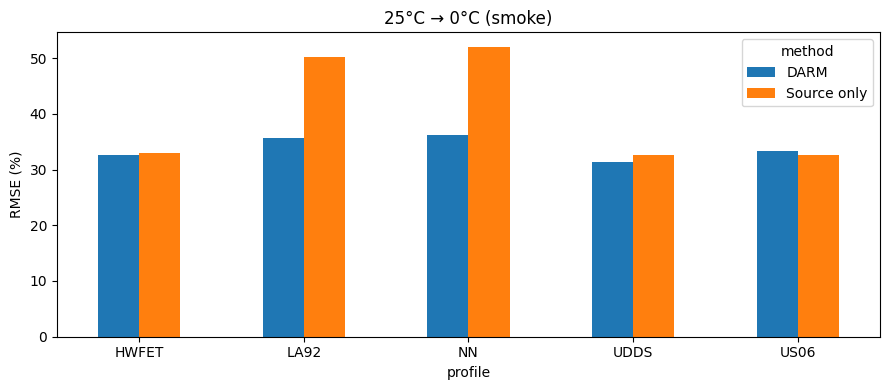

In [ ]:
import json
import matplotlib.pyplot as plt

result = json.loads((run_output / "results.json").read_text())
rows = []
for method, key in [("Source only", "target_source_only"), ("DARM", "target_darm")]:
    for profile, metrics in result[key].items():
        rows.append({"method": method, "profile": profile, **metrics})
metrics = pd.DataFrame(rows)
display(metrics)
metrics.pivot(index="profile", columns="method", values="rmse_percent").plot.bar(
    ylabel="RMSE (%)", rot=0, figsize=(9, 4)
)
plt.title(f"25°C → 0°C ({RUN_MODE})")
plt.tight_layout()
plt.show()


## Adaptation diagnostic

This optional run reuses the frozen formal source artifact, keeps the source BatchNorm state frozen, and evaluates selected adaptation epochs. Target labels are used only for post-epoch diagnosis, never for optimization, early stopping, or checkpoint selection.

In [ ]:
diagnostic_output = OUTPUT_ROOT / "diagnostic_bn_frozen"
source_artifact = OUTPUT_ROOT / "formal" / "source_artifact.pt"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

diagnostic_command = [
    sys.executable,
    str(script),
    "--manifest", str(MANIFEST),
    "--data-root", str(DATA_ROOT),
    "--output", str(diagnostic_output),
    "--source-artifact", str(source_artifact),
    "--device", "cuda",
    "--seed", str(SEED),
    "--diagnose-adaptation",
    "--resume",
]
print(" ".join(diagnostic_command))
subprocess.run(diagnostic_command, cwd=REPO_ROOT, check=True)

diagnostic = json.loads((diagnostic_output / "results.json").read_text())
rows = [
    {"epoch": 0, "profile": profile, **values}
    for profile, values in diagnostic["target_source_only"].items()
]
for checkpoint in diagnostic["adaptation_diagnostics"]:
    rows.extend(
        {"epoch": checkpoint["epoch"], "profile": profile, **values}
        for profile, values in checkpoint["target_test"].items()
    )
trajectory = pd.DataFrame(rows)
display(trajectory)
trajectory.groupby("epoch")["rmse_percent"].mean().plot(
    marker="o", ylabel="Mean profile RMSE (%)", grid=True, figsize=(8, 4)
)
plt.title("0°C adaptation trajectory")
plt.tight_layout()
plt.show()

display(pd.DataFrame(diagnostic["normalized_feature_ranges"]["target_adapt"]).T)


/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_bn_frozen --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal/source_artifact.pt --device cuda --seed 42 --diagnose-adaptation --resume


KeyError: 'target_test'

## Normalization / reconstruction A/B

These two diagnostic runs reuse the same formal source artifact. The first clips source-normalized inputs to `[0, 1]`; the second leaves normalization unchanged and sets the reconstruction weight to zero.

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
source_artifact = OUTPUT_ROOT / "formal" / "source_artifact.pt"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

experiments = {
    "clip_to_0_1": (OUTPUT_ROOT / "diagnostic_clip", ["--clip-normalized-inputs"]),
    "alpha_0": (OUTPUT_ROOT / "diagnostic_no_reconstruction", ["--alpha", "0"]),
}
ab_rows = []
for experiment, (experiment_output, extra_args) in experiments.items():
    command = [
        sys.executable,
        str(script),
        "--manifest", str(manifest_path),
        "--data-root", str(DATA_ROOT),
        "--output", str(experiment_output),
        "--source-artifact", str(source_artifact),
        "--device", "cuda",
        "--seed", str(SEED),
        "--diagnose-adaptation",
        "--resume",
        *extra_args,
    ]
    print(" ".join(command))
    subprocess.run(command, cwd=REPO_ROOT, check=True)
    result = json.loads((experiment_output / "results.json").read_text())
    ab_rows.extend(
        {"experiment": experiment, "epoch": 0, "profile": profile, **metrics}
        for profile, metrics in result["target_source_only"].items()
    )
    for checkpoint in result["adaptation_diagnostics"]:
        ab_rows.extend(
            {
                "experiment": experiment,
                "epoch": checkpoint["epoch"],
                "profile": profile,
                **metrics,
            }
            for profile, metrics in checkpoint["target_test"].items()
        )

ab_trajectory = pd.DataFrame(ab_rows)
ab_summary = (
    ab_trajectory.groupby(["experiment", "epoch"], as_index=False)["rmse_percent"]
    .mean()
    .rename(columns={"rmse_percent": "mean_profile_rmse_percent"})
)
display(ab_summary)
ab_summary.pivot(index="epoch", columns="experiment", values="mean_profile_rmse_percent").plot(
    marker="o", ylabel="Mean profile RMSE (%)", grid=True, figsize=(8, 4)
)
plt.title("0°C adaptation A/B")
plt.tight_layout()
plt.show()


## Alignment loss isolation

These runs disable reconstruction and isolate adversarial alignment from MK-MMD alignment.

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
source_artifact = OUTPUT_ROOT / "formal" / "source_artifact.pt"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

loss_experiments = {
    "adversarial_only": (
        OUTPUT_ROOT / "diagnostic_adversarial_only",
        ["--adversarial-weight", "1", "--alpha", "0", "--beta", "0"],
    ),
    "mmd_only": (
        OUTPUT_ROOT / "diagnostic_mmd_only",
        ["--adversarial-weight", "0", "--alpha", "0", "--beta", "1"],
    ),
}
loss_rows = []
for experiment, (experiment_output, weights) in loss_experiments.items():
    command = [
        sys.executable,
        str(script),
        "--manifest", str(manifest_path),
        "--data-root", str(DATA_ROOT),
        "--output", str(experiment_output),
        "--source-artifact", str(source_artifact),
        "--device", "cuda",
        "--seed", str(SEED),
        "--diagnose-adaptation",
        "--resume",
        *weights,
    ]
    print(" ".join(command))
    subprocess.run(command, cwd=REPO_ROOT, check=True)
    result = json.loads((experiment_output / "results.json").read_text())
    loss_rows.extend(
        {"experiment": experiment, "epoch": 0, "profile": profile, **metrics}
        for profile, metrics in result["target_source_only"].items()
    )
    for checkpoint in result["adaptation_diagnostics"]:
        loss_rows.extend(
            {
                "experiment": experiment,
                "epoch": checkpoint["epoch"],
                "profile": profile,
                **metrics,
            }
            for profile, metrics in checkpoint["target_test"].items()
        )

loss_trajectory = pd.DataFrame(loss_rows)
loss_summary = (
    loss_trajectory.groupby(["experiment", "epoch"], as_index=False)["rmse_percent"]
    .mean()
    .rename(columns={"rmse_percent": "mean_profile_rmse_percent"})
)
display(loss_summary)
loss_summary.pivot(index="epoch", columns="experiment", values="mean_profile_rmse_percent").plot(
    marker="o", ylabel="Mean profile RMSE (%)", grid=True, figsize=(8, 4)
)
plt.title("0°C alignment-loss isolation")
plt.tight_layout()
plt.show()


## Target Cycle 1 normalization diagnostic

The paper states that measurements are min-max normalized to `[0, 1]` but does not identify the fitting scope. This diagnostic fits a separate target scaler using only unlabeled target Cycle 1; no target SOC or target-test statistics are used.

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
source_artifact = OUTPUT_ROOT / "formal" / "source_artifact.pt"
target_normalized_output = OUTPUT_ROOT / "diagnostic_target_normalized"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

command = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--output", str(target_normalized_output),
    "--source-artifact", str(source_artifact),
    "--target-normalization", "target_adapt",
    "--device", "cuda",
    "--seed", str(SEED),
    "--diagnose-adaptation",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

target_normalized = json.loads((target_normalized_output / "results.json").read_text())
normalization_rows = [
    {"epoch": 0, "profile": profile, **metrics}
    for profile, metrics in target_normalized["target_source_only"].items()
]
for checkpoint in target_normalized["adaptation_diagnostics"]:
    normalization_rows.extend(
        {"epoch": checkpoint["epoch"], "profile": profile, **metrics}
        for profile, metrics in checkpoint["target_test"].items()
    )

normalization_trajectory = pd.DataFrame(normalization_rows)
normalization_summary = (
    normalization_trajectory.groupby("epoch", as_index=False)["rmse_percent"]
    .mean()
    .rename(columns={"rmse_percent": "mean_profile_rmse_percent"})
)
display(normalization_summary)
normalization_summary.plot(
    x="epoch", y="mean_profile_rmse_percent", marker="o", grid=True, figsize=(8, 4)
)
plt.ylabel("Mean profile RMSE (%)")
plt.title("0°C target-normalized adaptation")
plt.tight_layout()
plt.show()
display(pd.DataFrame(target_normalized["normalized_feature_ranges"]["target_adapt"]).T)


## Target-domain normalization diagnostic

This transductive diagnostic fits one min-max scaler on all 0°C input covariates. It never reads target SOC labels, but it does use target-test feature ranges and is therefore not the leakage-free default protocol.

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
source_artifact = OUTPUT_ROOT / "formal" / "source_artifact.pt"
target_domain_output = OUTPUT_ROOT / "diagnostic_target_domain_normalized"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

command = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--output", str(target_domain_output),
    "--source-artifact", str(source_artifact),
    "--target-normalization", "target_domain",
    "--device", "cuda",
    "--seed", str(SEED),
    "--diagnose-adaptation",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

target_domain = json.loads((target_domain_output / "results.json").read_text())
domain_rows = [
    {"epoch": 0, "profile": profile, **metrics}
    for profile, metrics in target_domain["target_source_only"].items()
]
for checkpoint in target_domain["adaptation_diagnostics"]:
    domain_rows.extend(
        {"epoch": checkpoint["epoch"], "profile": profile, **metrics}
        for profile, metrics in checkpoint["target_test"].items()
    )

domain_trajectory = pd.DataFrame(domain_rows)
domain_summary = (
    domain_trajectory.groupby("epoch", as_index=False)["rmse_percent"]
    .mean()
    .rename(columns={"rmse_percent": "mean_profile_rmse_percent"})
)
display(domain_summary)
domain_summary.plot(
    x="epoch", y="mean_profile_rmse_percent", marker="o", grid=True, figsize=(8, 4)
)
plt.ylabel("Mean profile RMSE (%)")
plt.title("0°C target-domain-normalized adaptation")
plt.tight_layout()
plt.show()
display(pd.DataFrame(target_domain["normalized_feature_ranges"]["target_adapt"]).T)


## Full rerun with the paper feature order

The paper defines each input as `[current, voltage, temperature]`. This full run trains a separate source artifact with that order and then performs the 25°C → 0°C adaptation. It never overwrites the original formal run.

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
paper_order_output = OUTPUT_ROOT / "formal_paper_ivt"
command = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--output", str(paper_order_output),
    "--feature-order", "paper_ivt",
    "--device", "cuda",
    "--seed", str(SEED),
    "--diagnose-adaptation",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

paper_order = json.loads((paper_order_output / "results.json").read_text())
source_rows = [
    {"profile": profile, **metrics}
    for profile, metrics in paper_order["source_test"].items()
]
display(pd.DataFrame(source_rows))

target_rows = []
for method, key in (("Source only", "target_source_only"), ("DARM", "target_darm")):
    target_rows.extend(
        {"method": method, "profile": profile, **metrics}
        for profile, metrics in paper_order[key].items()
    )
paper_order_metrics = pd.DataFrame(target_rows)
display(paper_order_metrics)
paper_order_metrics.pivot(
    index="profile", columns="method", values="rmse_percent"
).plot.bar(ylabel="RMSE (%)", rot=0, figsize=(9, 4))
plt.title("25°C → 0°C with paper feature order")
plt.tight_layout()
plt.show()


## Source checkpoint comparison

This diagnostic compares the paper-order source artifact, best training-loss checkpoint, and last checkpoint without retraining or adapting.

In [ ]:
import json
import subprocess
import sys

import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
paper_order_output = OUTPUT_ROOT / "formal_paper_ivt"
source_artifact = paper_order_output / "source_artifact.pt"
comparison_output = OUTPUT_ROOT / "diagnostic_source_checkpoints"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

command = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--output", str(comparison_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--compare-source-checkpoints",
    "--device", "cuda",
    "--seed", str(SEED),
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

comparison = json.loads(
    (comparison_output / "source_checkpoint_comparison.json").read_text()
)
checkpoint_rows = []
for checkpoint_name, checkpoint in comparison["checkpoints"].items():
    for split in ("source_test", "target_source_only"):
        checkpoint_rows.extend(
            {
                "checkpoint": checkpoint_name,
                "split": split,
                "profile": profile,
                **metrics,
            }
            for profile, metrics in checkpoint[split].items()
        )

checkpoint_metrics = pd.DataFrame(checkpoint_rows)
display(checkpoint_metrics)
checkpoint_summary = (
    checkpoint_metrics.groupby(["checkpoint", "split"], as_index=False)["rmse_percent"]
    .mean()
    .rename(columns={"rmse_percent": "mean_profile_rmse_percent"})
)
display(checkpoint_summary)


## SOC-label and source-scaler audit

This diagnostic compares the current per-file Ah SOC labels with 2.75 Ah and 2.9 Ah capacity references, and reports source-scaler range violations. It does not train or adapt a model.

In [ ]:
import json
import subprocess
import sys

import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
paper_order_output = OUTPUT_ROOT / "formal_paper_ivt"
source_artifact = paper_order_output / "source_artifact.pt"
audit_output = OUTPUT_ROOT / "diagnostic_preprocessing_audit"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

command = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--output", str(audit_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--audit-preprocessing",
    "--device", "cuda",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

audit = json.loads((audit_output / "preprocessing_audit.json").read_text())
label_comparison = pd.DataFrame(audit["label_formula_comparison"])
display(label_comparison[label_comparison.role.isin(["source_train", "source_test"])])

range_rows = []
for profile, features in audit["normalized_feature_ranges"]["source_test"].items():
    range_rows.extend(
        {"profile": profile, "feature": feature, **values}
        for feature, values in features.items()
    )
source_test_ranges = pd.DataFrame(range_rows)
display(source_test_ranges)
display(
    source_test_ranges.pivot(
        index="profile", columns="feature", values="outside_0_1_fraction"
    )
)


/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_preprocessing_audit --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_ivt/source_artifact.pt --feature-order paper_ivt --audit-preprocessing --device cuda


,role,profile,record_id,soc_denominator_ah,delivered_ah,soc_end_per_file_percent,soc_end_2_75ah_percent,mae_per_file_vs_2_75ah_percent,soc_end_2_9ah_percent,mae_per_file_vs_2_9ah_percent
0,source_train,Cycle_1,source_train_cycle_1,2.69557,2.69557,0.0,1.979273,0.943416,7.049310,3.360039
1,source_train,Cycle_2,source_train_cycle_2,2.71140,2.71132,0.0,1.406545,0.714614,6.506207,3.300289
2,source_train,Cycle_3,source_train_cycle_3,2.53031,2.53027,0.0,7.990182,4.087937,12.749310,6.522343
3,source_train,Cycle_4,source_train_cycle_4,2.79817,2.79817,0.0,-1.751636,0.886394,3.511379,1.776891
4,source_test,LA92,source_test_la92,2.58703,2.58703,0.0,5.926182,2.951382,10.792069,5.374712
5,source_test,UDDS,source_test_udds,2.70149,2.70149,0.0,1.764000,0.869631,6.845172,3.374590
6,source_test,US06,source_test_us06,2.58596,2.58596,0.0,5.965091,3.068674,10.828966,5.570839
7,source_test,HWFET,source_test_hwfet_a,2.70808,2.70808,0.0,1.524364,0.761568,6.617931,3.306299
8,source_test,HWFET,source_test_hwfet_b,2.70304,2.70304,0.0,1.707636,0.853788,6.791724,3.395741
9,source_test,NN,source_test_nn,2.54962,2.54962,0.0,7.286545,3.643935,12.082069,6.042133


,profile,feature,min,max,outside_0_1_fraction
0,LA92,current,0.310788,0.970648,0.000000
1,LA92,voltage,0.048330,0.997320,0.000000
2,LA92,temperature,0.466945,0.748431,0.000000
3,UDDS,current,0.395646,0.788087,0.000000
4,UDDS,voltage,0.035982,0.996521,0.000000
5,UDDS,temperature,0.465585,0.645083,0.000000
6,US06,current,-0.032440,0.903944,0.000209
7,US06,voltage,0.069078,0.996899,0.000000
8,US06,temperature,0.464225,1.333159,0.282159
9,HWFET,current,0.456396,0.830556,0.000000


feature,current,temperature,voltage
profile,,,
HWFET,0.000000,0.000000,0.000066
LA92,0.000000,0.000000,0.000000
NN,0.000000,0.000000,0.000000
UDDS,0.000000,0.000000,0.000000
US06,0.000209,0.282159,0.000000


In [ ]:
# Run the BN/adversarial update-semantics diagnostic suite on Colab L4.
import hashlib
import json
import os
import shutil
import subprocess
import sys
from getpass import getpass
from pathlib import Path

import pandas as pd
import torch
from google.colab import drive, userdata

drive.mount("/content/drive")

repo_root = Path("/content/battery-soc-transfer-benchmark")
repo_url = "https://github.com/zhangcastle/battery-soc-transfer-benchmark.git"
drive_root = Path("/content/drive/MyDrive/battery_soc_benchmark")
data_root = drive_root / "data/raw/Panasonic_18650PF"
liu_root = drive_root / "outputs/liu_2025/25c_to_0c"
suite_root = liu_root / "diagnostic_update_semantics_20260728"
source_artifact = liu_root / "formal_paper_ivt/source_artifact.pt"
bundle = suite_root / "liu_2025_update_semantics_code.tar.gz"
expected_bundle_sha256 = "70e300c211f45a8a48ae7af75a954e9d0fd30cd005d9be5007b941a0463639e3"

assert torch.cuda.is_available(), "A CUDA runtime is required"
gpu_name = torch.cuda.get_device_name(0)
assert "L4" in gpu_name, f"Expected an L4 runtime, got: {gpu_name}"
assert data_root.is_dir(), f"Missing data root: {data_root}"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
assert bundle.is_file(), f"Missing diagnostic code bundle: {bundle}"
assert hashlib.sha256(bundle.read_bytes()).hexdigest() == expected_bundle_sha256
print(f"GPU: {gpu_name}")

token = os.environ.get("GITHUB_TOKEN")
if not token:
    try:
        token = userdata.get("GITHUB_TOKEN")
    except Exception:
        token = None
if not token:
    token = getpass("GitHub token: ")
assert token, "GITHUB_TOKEN is unavailable"
subprocess.run(
    ["gh", "auth", "login", "--hostname", "github.com", "--with-token"],
    input=token,
    text=True,
    check=True,
)
subprocess.run(["gh", "auth", "setup-git"], check=True)
if repo_root.exists():
    subprocess.run(["git", "-C", str(repo_root), "pull", "--ff-only", "origin", "main"], check=True)
else:
    subprocess.run(["git", "clone", repo_url, str(repo_root)], check=True)
subprocess.run(["tar", "-xzf", str(bundle), "-C", str(repo_root)], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(repo_root)], check=True)

subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/reproductions/liu_2025/test_darm.py",
        "tests/reproductions/liu_2025/test_source_artifact.py",
        "tests/reproductions/liu_2025/test_run_reproduction.py",
        "-q",
    ],
    cwd=repo_root,
    check=True,
)

script = repo_root / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest = repo_root / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
common = [
    sys.executable,
    str(script),
    "--manifest", str(manifest),
    "--data-root", str(data_root),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--seed", "42",
    "--device", "cuda",
]
experiments = [
    (
        "bn_forward_audit",
        ["--audit-target-bn-forward"],
        "target_bn_forward_audit.json",
    ),
    (
        "adversarial_grl_legacy",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "1", "--alpha", "0", "--beta", "0", "--target-bn-mode", "legacy", "--adversarial-update", "grl_joint"],
        "results.json",
    ),
    (
        "adversarial_grl_frozen_stats",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "1", "--alpha", "0", "--beta", "0", "--target-bn-mode", "frozen_stats", "--adversarial-update", "grl_joint"],
        "results.json",
    ),
    (
        "adversarial_alternating_frozen_stats",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "1", "--alpha", "0", "--beta", "0", "--target-bn-mode", "frozen_stats", "--adversarial-update", "alternating_flipped"],
        "results.json",
    ),
    (
        "adversarial_eq12_frozen_stats",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "1", "--alpha", "0", "--beta", "0", "--target-bn-mode", "frozen_stats", "--adversarial-update", "eq12_joint"],
        "results.json",
    ),
    (
        "mmd_legacy",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "0", "--alpha", "0", "--beta", "1", "--target-bn-mode", "legacy", "--adversarial-update", "grl_joint"],
        "results.json",
    ),
    (
        "mmd_frozen_stats",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "0", "--alpha", "0", "--beta", "1", "--target-bn-mode", "frozen_stats", "--adversarial-update", "grl_joint"],
        "results.json",
    ),
]

suite_root.mkdir(parents=True, exist_ok=True)
for name, arguments, completion_file in experiments:
    output = suite_root / name
    if (output / completion_file).is_file():
        print(f"Skipping completed experiment: {name}")
        continue
    output.mkdir(parents=True, exist_ok=True)
    command = [*common, "--output", str(output), *arguments]
    print(f"\nRunning: {name}\n{' '.join(command)}")
    subprocess.run(command, cwd=repo_root, check=True)

summary_rows = []
for name, _, completion_file in experiments:
    result = json.loads((suite_root / name / completion_file).read_text())
    if completion_file == "target_bn_forward_audit.json":
        summary_rows.append(
            {
                "experiment": name,
                "mean_rmse_percent": sum(row["rmse_after_legacy_bn_forward"] for row in result["profiles"]) / len(result["profiles"]),
            }
        )
    else:
        training = result["target_training"]
        summary_rows.append(
            {
                "experiment": name,
                "mean_rmse_percent": training["mean_profile_rmse_percent"],
                "domain_accuracy": training["overall_domain_accuracy"],
                "p_source_given_target": training["mean_p_source_given_target"],
                "adversarial_gradient_l2": training["gradient_l2"]["adversarial"],
                "mmd_gradient_l2": training["gradient_l2"]["mmd"],
            }
        )
display(pd.DataFrame(summary_rows))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA L4

Running: bn_forward_audit
/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_ivt/source_artifact.pt --feature-order paper_ivt --seed 42 --device cuda --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_update_semantics_20260728/bn_forward_audit --audit-target-bn-forward

Running: adversarial_grl_legacy
/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/mani

,experiment,mean_rmse_percent,domain_accuracy,p_source_given_target,adversarial_gradient_l2,mmd_gradient_l2
0,bn_forward_audit,15.108423,NaN,NaN,NaN,NaN
1,adversarial_grl_legacy,15.069151,0.522616,0.506180,0.072820,0.000000
2,adversarial_grl_frozen_stats,7.912967,0.520910,0.529624,0.499420,0.000000
3,adversarial_alternating_frozen_stats,7.721993,0.515745,0.530219,0.891612,0.000000
4,adversarial_eq12_frozen_stats,13.783906,0.759283,0.467151,0.499420,0.000000
5,mmd_legacy,14.710135,0.511654,0.525209,0.000000,0.351380
6,mmd_frozen_stats,8.117056,0.477603,0.530391,0.000000,8.270257


## Frozen-BN full-loss 10-epoch diagnostic

This short run keeps the paper loss weights and uses `frozen_stats + grl_joint`. Target SOC labels are used only for post-epoch diagnostic evaluation, never for optimization or checkpoint selection.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_ivt/source_artifact.pt --feature-order paper_ivt --seed 42 --device cuda --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_frozen_stats_grl_full_loss_10ep --transfer-epochs 10 --patience 0 --adversarial-weight 1 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update grl_joint --resume


,epoch,mean_rmse_percent,total_loss,adversarial_loss,reconstruction_loss,mmd_loss,domain_accuracy,p_source_given_target,total_gradient_l2,target_feature_rms_drift,bn_mean_drift,bn_var_drift,bn_batches_drift
0,1,8.462688,26.770454,0.667242,2.582644,0.276770,0.623956,0.506019,82.965227,0.251959,0.0,0.0,0
1,2,7.722036,24.649266,0.612262,2.378578,0.251225,0.708402,0.465382,77.024532,0.268938,0.0,0.0,0
2,3,7.441435,22.868359,0.566848,2.206602,0.235490,0.749832,0.427482,92.009457,0.344741,0.0,0.0,0
3,4,7.464361,21.322459,0.522484,2.058255,0.217422,0.772709,0.390741,81.745340,0.345169,0.0,0.0,0
4,5,6.743344,19.885252,0.472124,1.920509,0.208038,0.804655,0.354279,37.101257,0.406253,0.0,0.0,0
5,6,7.400295,18.501803,0.418906,1.787838,0.204521,0.844159,0.319102,55.661541,0.428267,0.0,0.0,0
6,7,7.216065,17.252184,0.370504,1.668418,0.197503,0.869863,0.287587,49.549054,0.459597,0.0,0.0,0
7,8,7.227601,16.103228,0.333362,1.557669,0.193173,0.878699,0.257506,23.931230,0.468932,0.0,0.0,0
8,9,7.281037,15.023433,0.321935,1.451871,0.182793,0.877596,0.239197,30.999268,0.506942,0.0,0.0,0
9,10,7.240765,14.032507,0.317884,1.353539,0.179228,0.871456,0.230155,55.594200,0.531779,0.0,0.0,0


,epoch,profile,rmse_percent,mae_percent,n_windows
0,1,LA92,6.094450,4.426822,15368
1,1,UDDS,6.434844,5.129154,12831
2,1,US06,11.848049,10.660053,3635
3,1,HWFET,11.629197,10.826933,5961
4,1,NN,6.306900,4.429025,13439
5,2,LA92,5.471778,3.859115,15368
6,2,UDDS,5.817927,4.454423,12831
7,2,US06,11.057565,9.844778,3635
8,2,HWFET,10.515580,9.681123,5961
9,2,NN,5.747328,3.937466,13439


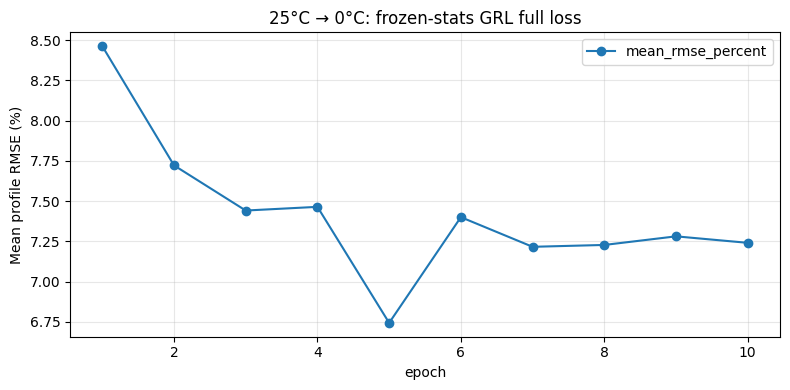

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

diagnostic_output = OUTPUT_ROOT / "diagnostic_frozen_stats_grl_full_loss_10ep"
source_artifact = OUTPUT_ROOT / "formal_paper_ivt/source_artifact.pt"
script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
diagnostic_output.mkdir(parents=True, exist_ok=True)
if not (diagnostic_output / "results.json").is_file():
    command = [
        sys.executable,
        str(script),
        "--manifest", str(manifest_path),
        "--data-root", str(DATA_ROOT),
        "--source-artifact", str(source_artifact),
        "--feature-order", "paper_ivt",
        "--seed", "42",
        "--device", "cuda",
        "--output", str(diagnostic_output),
        "--transfer-epochs", "10",
        "--patience", "0",
        "--adversarial-weight", "1",
        "--alpha", "10",
        "--beta", "1",
        "--target-bn-mode", "frozen_stats",
        "--adversarial-update", "grl_joint",
        "--resume",
    ]
    print(" ".join(command))
    subprocess.run(command, cwd=REPO_ROOT, check=True)
else:
    print(f"Using completed result: {diagnostic_output}")

result = json.loads((diagnostic_output / "results.json").read_text())
diagnostics = result["adaptation_diagnostics"]
assert result["target_bn_mode"] == "frozen_stats"
assert result["adversarial_update"] == "grl_joint"

epoch_rows = []
profile_rows = []
for record in diagnostics:
    training = record["training"]
    bn_drift = training["target_bn_running_stat_drift"]
    epoch_rows.append(
        {
            "epoch": record["epoch"],
            "mean_rmse_percent": training["mean_profile_rmse_percent"],
            "total_loss": training["total"],
            "adversarial_loss": training["adversarial"],
            "reconstruction_loss": training["reconstruction"],
            "mmd_loss": training["mmd"],
            "domain_accuracy": training["overall_domain_accuracy"],
            "p_source_given_target": training["mean_p_source_given_target"],
            "total_gradient_l2": training["gradient_l2"]["total"],
            "target_feature_rms_drift": training["target_feature_rms_drift"],
            "bn_mean_drift": bn_drift["max_running_mean_abs_change"],
            "bn_var_drift": bn_drift["max_running_var_abs_change"],
            "bn_batches_drift": bn_drift["max_num_batches_tracked_change"],
        }
    )
    if record["epoch"] in {1, 2, 5, 10}:
        for profile, metrics in training["target_test"].items():
            profile_rows.append({"epoch": record["epoch"], "profile": profile, **metrics})

epochs = pd.DataFrame(epoch_rows)
profiles = pd.DataFrame(profile_rows)
display(epochs)
display(profiles)
assert not epochs[["bn_mean_drift", "bn_var_drift", "bn_batches_drift"]].to_numpy().any()
epochs.plot(x="epoch", y="mean_rmse_percent", marker="o", ylabel="Mean profile RMSE (%)", figsize=(8, 4))
plt.title("25°C → 0°C: frozen-stats GRL full loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Full-loss component/update ablation

These two ten-epoch runs isolate the contribution of GRL and compare it with the alternating flipped-label update. They reuse the same source checkpoint, seed, data order, loss weights, and frozen target BN statistics. Target SOC remains diagnostic-only.


Running: reconstruction_mmd
/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_ivt/source_artifact.pt --feature-order paper_ivt --seed 42 --device cuda --transfer-epochs 10 --patience 0 --alpha 10 --beta 1 --target-bn-mode frozen_stats --resume --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_frozen_stats_reconstruction_mmd_10ep --adversarial-weight 0 --adversarial-update grl_joint

Running: alternating_flipped
/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_t

,experiment,epoch,mean_rmse_percent,domain_accuracy,p_source_given_target,adversarial_gradient_l2,reconstruction_gradient_l2,mmd_gradient_l2,target_feature_rms_drift,bn_mean_drift,bn_var_drift,bn_batches_drift
0,grl_joint,1,8.462688,0.623956,0.506019,0.499420,76.229216,8.270257,0.251959,0.0,0.0,0
1,grl_joint,2,7.722036,0.708402,0.465382,2.257898,88.775526,13.556035,0.268938,0.0,0.0,0
4,grl_joint,5,6.743344,0.804655,0.354279,8.514644,32.051673,11.605967,0.406253,0.0,0.0,0
9,grl_joint,10,7.240765,0.871456,0.230155,1.928682,47.899911,7.899761,0.531779,0.0,0.0,0
10,reconstruction_mmd,1,8.391565,0.441598,0.536356,0.000000,76.229216,8.270257,0.204823,0.0,0.0,0
11,reconstruction_mmd,2,8.286125,0.438415,0.534655,0.000000,53.042201,13.076584,0.275882,0.0,0.0,0
14,reconstruction_mmd,5,7.335782,0.440005,0.534287,0.000000,32.834618,12.045415,0.378920,0.0,0.0,0
19,reconstruction_mmd,10,6.913695,0.441983,0.535050,0.000000,64.895228,7.998296,0.453634,0.0,0.0,0
20,alternating_flipped,1,8.076135,0.625332,0.506642,0.891612,76.229216,8.270257,0.212418,0.0,0.0,0
21,alternating_flipped,2,7.569222,0.706263,0.469620,4.041168,382.001206,11.976403,0.319490,0.0,0.0,0


,experiment,profile,rmse_percent,mae_percent,n_windows
0,grl_joint,LA92,5.126106,3.591075,15368
1,grl_joint,UDDS,5.941535,4.618181,12831
2,grl_joint,US06,9.979188,8.709743,3635
3,grl_joint,HWFET,9.777336,8.803091,5961
4,grl_joint,NN,5.379658,3.693139,13439
5,reconstruction_mmd,LA92,4.905757,3.435701,15368
6,reconstruction_mmd,UDDS,5.704940,4.468042,12831
7,reconstruction_mmd,US06,9.615158,8.310474,3635
8,reconstruction_mmd,HWFET,9.208977,8.304117,5961
9,reconstruction_mmd,NN,5.133642,3.500181,13439


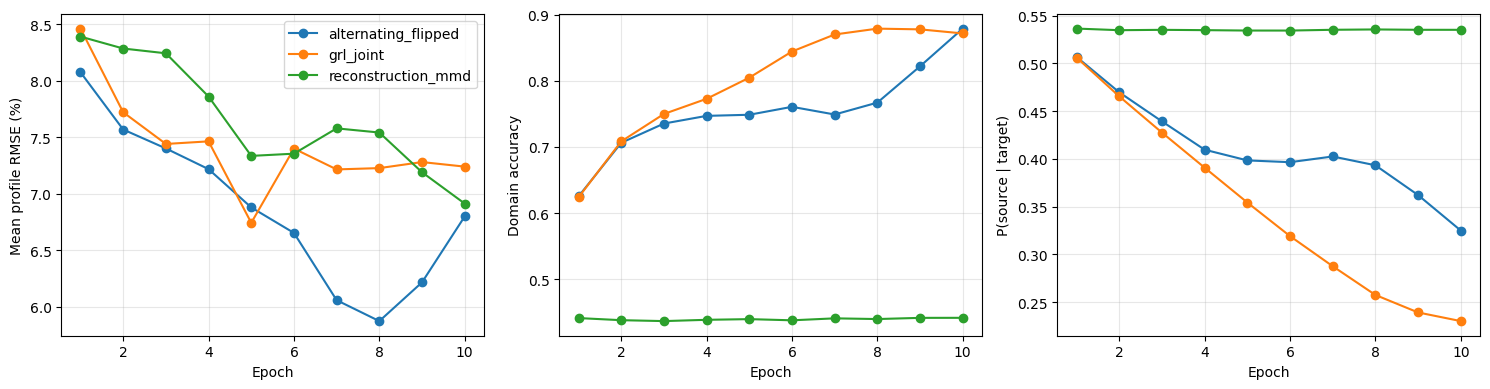

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = OUTPUT_ROOT / "formal_paper_ivt/source_artifact.pt"
script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

common = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--seed", "42",
    "--device", "cuda",
    "--transfer-epochs", "10",
    "--patience", "0",
    "--alpha", "10",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--resume",
]
experiments = {
    "grl_joint": (
        OUTPUT_ROOT / "diagnostic_frozen_stats_grl_full_loss_10ep",
        None,
    ),
    "reconstruction_mmd": (
        OUTPUT_ROOT / "diagnostic_frozen_stats_reconstruction_mmd_10ep",
        ["--adversarial-weight", "0", "--adversarial-update", "grl_joint"],
    ),
    "alternating_flipped": (
        OUTPUT_ROOT / "diagnostic_frozen_stats_alternating_full_loss_10ep",
        ["--adversarial-weight", "1", "--adversarial-update", "alternating_flipped"],
    ),
}

for name, (output, arguments) in experiments.items():
    if arguments is None:
        assert (output / "results.json").is_file(), f"Missing completed GRL baseline: {output}"
        continue
    output.mkdir(parents=True, exist_ok=True)
    if (output / "results.json").is_file():
        print(f"Using completed result: {name}")
        continue
    command = [*common, "--output", str(output), *arguments]
    print(f"\nRunning: {name}\n{' '.join(command)}")
    subprocess.run(command, cwd=REPO_ROOT, check=True)

epoch_rows = []
profile_rows = []
for name, (output, _) in experiments.items():
    result = json.loads((output / "results.json").read_text())
    assert result["target_bn_mode"] == "frozen_stats"
    for record in result["adaptation_diagnostics"]:
        training = record["training"]
        gradients = training["gradient_l2"]
        bn_drift = training["target_bn_running_stat_drift"]
        epoch_rows.append(
            {
                "experiment": name,
                "epoch": record["epoch"],
                "mean_rmse_percent": training["mean_profile_rmse_percent"],
                "domain_accuracy": training["overall_domain_accuracy"],
                "p_source_given_target": training["mean_p_source_given_target"],
                "adversarial_gradient_l2": gradients["adversarial"],
                "reconstruction_gradient_l2": gradients["reconstruction"],
                "mmd_gradient_l2": gradients["mmd"],
                "target_feature_rms_drift": training["target_feature_rms_drift"],
                "bn_mean_drift": bn_drift["max_running_mean_abs_change"],
                "bn_var_drift": bn_drift["max_running_var_abs_change"],
                "bn_batches_drift": bn_drift["max_num_batches_tracked_change"],
            }
        )
        if record["epoch"] == 10:
            for profile, metrics in training["target_test"].items():
                profile_rows.append({"experiment": name, "profile": profile, **metrics})

epochs = pd.DataFrame(epoch_rows)
profiles = pd.DataFrame(profile_rows)
display(epochs.loc[epochs.epoch.isin([1, 2, 5, 10])])
display(profiles)
assert not epochs[["bn_mean_drift", "bn_var_drift", "bn_batches_drift"]].to_numpy().any()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, group in epochs.groupby("experiment"):
    axes[0].plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
    axes[1].plot(group.epoch, group.domain_accuracy, marker="o", label=name)
    axes[2].plot(group.epoch, group.p_source_given_target, marker="o", label=name)
axes[0].set_ylabel("Mean profile RMSE (%)")
axes[1].set_ylabel("Domain accuracy")
axes[2].set_ylabel("P(source | target)")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.grid(True, alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


## Fully-frozen BN alternating diagnostic

This ten-epoch run differs from the preceding alternating experiment only by freezing target-BN affine parameters as well as running statistics. It tests whether late target-feature drift is caused by BN affine updates.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_ivt/source_artifact.pt --feature-order paper_ivt --seed 42 --device cuda --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_fully_frozen_alternating_full_loss_10ep --transfer-epochs 10 --patience 0 --adversarial-weight 1 --alpha 10 --beta 1 --target-bn-mode fully_frozen --adversarial-update alternating_flipped --resume


,target_bn_mode,epoch,mean_rmse_percent,domain_accuracy,p_source_given_target,adversarial_gradient_l2,reconstruction_gradient_l2,mmd_gradient_l2,target_feature_rms_drift,bn_mean_drift,bn_var_drift,bn_batches_drift
0,frozen_stats,1,8.076135,0.625332,0.506642,0.891612,76.229216,8.270257,0.212418,0.0,0.0,0
1,frozen_stats,2,7.569222,0.706263,0.469620,4.041168,382.001206,11.976403,0.319490,0.0,0.0,0
4,frozen_stats,5,6.879605,0.748627,0.398354,17.215349,84.662030,9.167600,0.568629,0.0,0.0,0
7,frozen_stats,8,5.873538,0.766988,0.393247,22.037187,80.158592,4.986731,0.808856,0.0,0.0,0
9,frozen_stats,10,6.799906,0.878791,0.324928,9.947481,37.452535,7.309632,0.913984,0.0,0.0,0
10,fully_frozen,1,9.394974,0.628588,0.503839,0.878214,75.606373,8.220932,0.310106,0.0,0.0,0
11,fully_frozen,2,8.223039,0.719457,0.458525,4.791858,61.437211,14.806563,0.250908,0.0,0.0,0
14,fully_frozen,5,7.198854,0.777816,0.387287,16.279589,80.212142,9.191789,0.532482,0.0,0.0,0
17,fully_frozen,8,6.678071,0.750596,0.394445,17.644186,71.661390,5.523154,0.816734,0.0,0.0,0
19,fully_frozen,10,7.624952,0.850799,0.321412,9.176814,29.249750,7.428716,0.912679,0.0,0.0,0


,target_bn_mode,profile,rmse_percent,mae_percent,n_windows
0,frozen_stats,LA92,5.158950,3.723498,15368
1,frozen_stats,UDDS,6.789664,5.254974,12831
2,frozen_stats,US06,8.888670,7.754727,3635
3,frozen_stats,HWFET,7.922236,6.726194,5961
4,frozen_stats,NN,5.240012,3.748261,13439
5,fully_frozen,LA92,5.859243,4.193862,15368
6,fully_frozen,UDDS,7.634945,5.930638,12831
7,fully_frozen,US06,9.495485,8.228287,3635
8,fully_frozen,HWFET,9.242591,7.880144,5961
9,fully_frozen,NN,5.892498,4.201434,13439


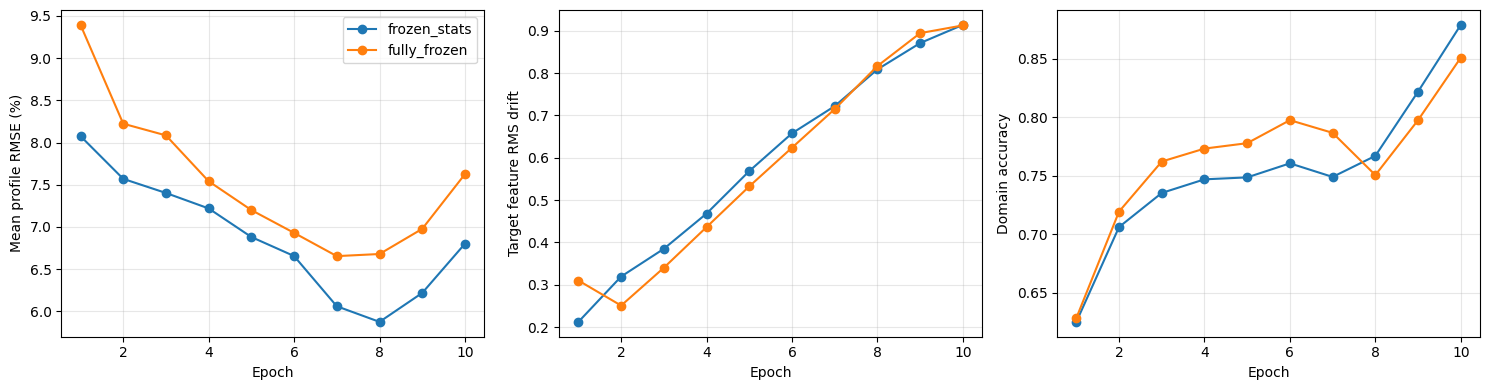

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = OUTPUT_ROOT / "formal_paper_ivt/source_artifact.pt"
script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
frozen_stats_output = OUTPUT_ROOT / "diagnostic_frozen_stats_alternating_full_loss_10ep"
fully_frozen_output = OUTPUT_ROOT / "diagnostic_fully_frozen_alternating_full_loss_10ep"

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
assert (frozen_stats_output / "results.json").is_file(), "Missing frozen-stats baseline"
fully_frozen_output.mkdir(parents=True, exist_ok=True)
if not (fully_frozen_output / "results.json").is_file():
    command = [
        sys.executable,
        str(script),
        "--manifest", str(manifest_path),
        "--data-root", str(DATA_ROOT),
        "--source-artifact", str(source_artifact),
        "--feature-order", "paper_ivt",
        "--seed", "42",
        "--device", "cuda",
        "--output", str(fully_frozen_output),
        "--transfer-epochs", "10",
        "--patience", "0",
        "--adversarial-weight", "1",
        "--alpha", "10",
        "--beta", "1",
        "--target-bn-mode", "fully_frozen",
        "--adversarial-update", "alternating_flipped",
        "--resume",
    ]
    print(" ".join(command))
    subprocess.run(command, cwd=REPO_ROOT, check=True)
else:
    print(f"Using completed result: {fully_frozen_output}")

experiments = {
    "frozen_stats": frozen_stats_output,
    "fully_frozen": fully_frozen_output,
}
epoch_rows = []
profile_rows = []
for name, output in experiments.items():
    result = json.loads((output / "results.json").read_text())
    assert result["target_bn_mode"] == name
    assert result["adversarial_update"] == "alternating_flipped"
    for record in result["adaptation_diagnostics"]:
        training = record["training"]
        gradients = training["gradient_l2"]
        bn_drift = training["target_bn_running_stat_drift"]
        epoch_rows.append(
            {
                "target_bn_mode": name,
                "epoch": record["epoch"],
                "mean_rmse_percent": training["mean_profile_rmse_percent"],
                "domain_accuracy": training["overall_domain_accuracy"],
                "p_source_given_target": training["mean_p_source_given_target"],
                "adversarial_gradient_l2": gradients["adversarial"],
                "reconstruction_gradient_l2": gradients["reconstruction"],
                "mmd_gradient_l2": gradients["mmd"],
                "target_feature_rms_drift": training["target_feature_rms_drift"],
                "bn_mean_drift": bn_drift["max_running_mean_abs_change"],
                "bn_var_drift": bn_drift["max_running_var_abs_change"],
                "bn_batches_drift": bn_drift["max_num_batches_tracked_change"],
            }
        )
        if record["epoch"] == 10:
            for profile, metrics in training["target_test"].items():
                profile_rows.append({"target_bn_mode": name, "profile": profile, **metrics})

epochs = pd.DataFrame(epoch_rows)
profiles = pd.DataFrame(profile_rows)
display(epochs.loc[epochs.epoch.isin([1, 2, 5, 8, 10])])
display(profiles)
assert not epochs[["bn_mean_drift", "bn_var_drift", "bn_batches_drift"]].to_numpy().any()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, group in epochs.groupby("target_bn_mode"):
    axes[0].plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
    axes[1].plot(group.epoch, group.target_feature_rms_drift, marker="o", label=name)
    axes[2].plot(group.epoch, group.domain_accuracy, marker="o", label=name)
axes[0].set_ylabel("Mean profile RMSE (%)")
axes[1].set_ylabel("Target feature RMS drift")
axes[2].set_ylabel("Domain accuracy")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.grid(True, alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


## Alternating adversarial-only 10-epoch diagnostic

This final update-semantics diagnostic removes reconstruction and MMD while retaining frozen target-BN statistics and alternating flipped-label updates. It distinguishes loss conflict from instability in the adversarial game itself.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_ivt/source_artifact.pt --feature-order paper_ivt --seed 42 --device cuda --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_frozen_stats_alternating_adversarial_only_10ep --transfer-epochs 10 --patience 0 --adversarial-weight 1 --alpha 0 --beta 0 --target-bn-mode frozen_stats --adversarial-update alternating_flipped --resume


,experiment,epoch,mean_rmse_percent,domain_accuracy,source_domain_accuracy,target_domain_accuracy,p_source_given_source,p_source_given_target,adversarial_loss,adversarial_gradient_l2,target_feature_rms_drift,bn_mean_drift,bn_var_drift,bn_batches_drift
0,full_loss,1,8.076135,0.625332,0.935156,0.309049,0.534765,0.506642,0.686035,0.891612,0.212418,0.0,0.0,0
1,full_loss,2,7.569222,0.706263,0.867746,0.543026,0.558476,0.469620,0.771748,4.041168,0.319490,0.0,0.0,0
4,full_loss,5,6.879605,0.748627,0.754464,0.741059,0.624098,0.398354,0.994366,17.215349,0.568629,0.0,0.0,0
7,full_loss,8,5.873538,0.766988,0.710156,0.827036,0.624148,0.393247,1.004247,22.037187,0.808856,0.0,0.0,0
9,full_loss,10,6.799906,0.878791,0.836272,0.921851,0.681992,0.324928,1.243364,9.947481,0.913984,0.0,0.0,0
10,adversarial_only,1,7.699450,0.515745,0.937054,0.084303,0.533894,0.530227,0.638705,0.891612,0.748366,0.0,0.0,0
11,adversarial_only,2,13.791790,0.416677,0.817746,0.005022,0.543775,0.558839,0.588580,2.208106,2.840899,0.0,0.0,0
14,adversarial_only,5,17.313681,0.655947,0.840960,0.469640,0.525366,0.507924,0.686763,0.743109,1.568615,0.0,0.0,0
17,adversarial_only,8,12.921461,0.543917,0.773996,0.301759,0.545812,0.514362,0.673776,3.582509,1.168976,0.0,0.0,0
19,adversarial_only,10,13.806710,0.749525,0.864062,0.631214,0.563132,0.485043,0.742395,1.402386,1.104411,0.0,0.0,0


,experiment,profile,rmse_percent,mae_percent,n_windows
0,full_loss,LA92,5.158950,3.723498,15368
1,full_loss,UDDS,6.789664,5.254974,12831
2,full_loss,US06,8.888670,7.754727,3635
3,full_loss,HWFET,7.922236,6.726194,5961
4,full_loss,NN,5.240012,3.748261,13439
5,adversarial_only,LA92,13.105088,12.078279,15368
6,adversarial_only,UDDS,12.228191,10.473100,12831
7,adversarial_only,US06,15.251726,13.275546,3635
8,adversarial_only,HWFET,14.563282,11.664062,5961
9,adversarial_only,NN,13.885262,12.842287,13439


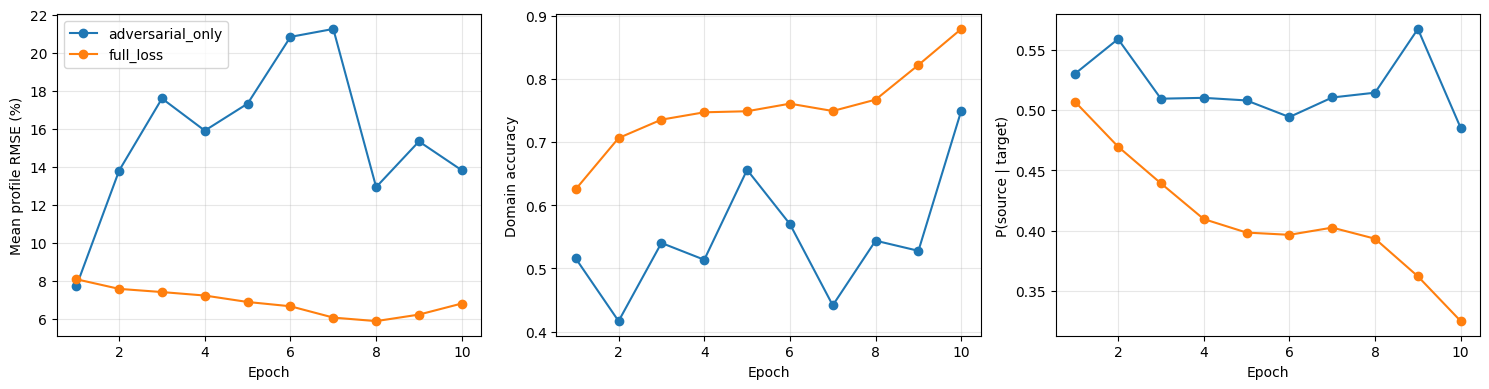

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = OUTPUT_ROOT / "formal_paper_ivt/source_artifact.pt"
script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
full_loss_output = OUTPUT_ROOT / "diagnostic_frozen_stats_alternating_full_loss_10ep"
adversarial_only_output = OUTPUT_ROOT / "diagnostic_frozen_stats_alternating_adversarial_only_10ep"

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
assert (full_loss_output / "results.json").is_file(), "Missing alternating full-loss baseline"
adversarial_only_output.mkdir(parents=True, exist_ok=True)
if not (adversarial_only_output / "results.json").is_file():
    command = [
        sys.executable,
        str(script),
        "--manifest", str(manifest_path),
        "--data-root", str(DATA_ROOT),
        "--source-artifact", str(source_artifact),
        "--feature-order", "paper_ivt",
        "--seed", "42",
        "--device", "cuda",
        "--output", str(adversarial_only_output),
        "--transfer-epochs", "10",
        "--patience", "0",
        "--adversarial-weight", "1",
        "--alpha", "0",
        "--beta", "0",
        "--target-bn-mode", "frozen_stats",
        "--adversarial-update", "alternating_flipped",
        "--resume",
    ]
    print(" ".join(command))
    subprocess.run(command, cwd=REPO_ROOT, check=True)
else:
    print(f"Using completed result: {adversarial_only_output}")

experiments = {
    "full_loss": full_loss_output,
    "adversarial_only": adversarial_only_output,
}
epoch_rows = []
profile_rows = []
for name, output in experiments.items():
    result = json.loads((output / "results.json").read_text())
    assert result["target_bn_mode"] == "frozen_stats"
    assert result["adversarial_update"] == "alternating_flipped"
    for record in result["adaptation_diagnostics"]:
        training = record["training"]
        gradients = training["gradient_l2"]
        bn_drift = training["target_bn_running_stat_drift"]
        epoch_rows.append(
            {
                "experiment": name,
                "epoch": record["epoch"],
                "mean_rmse_percent": training["mean_profile_rmse_percent"],
                "domain_accuracy": training["overall_domain_accuracy"],
                "source_domain_accuracy": training["source_domain_accuracy"],
                "target_domain_accuracy": training["target_domain_accuracy"],
                "p_source_given_source": training["mean_p_source_given_source"],
                "p_source_given_target": training["mean_p_source_given_target"],
                "adversarial_loss": training["adversarial"],
                "adversarial_gradient_l2": gradients["adversarial"],
                "target_feature_rms_drift": training["target_feature_rms_drift"],
                "bn_mean_drift": bn_drift["max_running_mean_abs_change"],
                "bn_var_drift": bn_drift["max_running_var_abs_change"],
                "bn_batches_drift": bn_drift["max_num_batches_tracked_change"],
            }
        )
        if record["epoch"] == 10:
            for profile, metrics in training["target_test"].items():
                profile_rows.append({"experiment": name, "profile": profile, **metrics})

epochs = pd.DataFrame(epoch_rows)
profiles = pd.DataFrame(profile_rows)
display(epochs.loc[epochs.epoch.isin([1, 2, 5, 8, 10])])
display(profiles)
assert not epochs[["bn_mean_drift", "bn_var_drift", "bn_batches_drift"]].to_numpy().any()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, group in epochs.groupby("experiment"):
    axes[0].plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
    axes[1].plot(group.epoch, group.domain_accuracy, marker="o", label=name)
    axes[2].plot(group.epoch, group.p_source_given_target, marker="o", label=name)
axes[0].set_ylabel("Mean profile RMSE (%)")
axes[1].set_ylabel("Domain accuracy")
axes[2].set_ylabel("P(source | target)")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.grid(True, alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


## Corrected source-protocol check

This source-only run uses the paper's channel order, one 25°C HWFET session, and a diagnostic source-domain min-max scaler so every 25°C input covariate is mapped to `[0, 1]`. It does not start target adaptation or overwrite earlier runs.

In [ ]:
import json
import subprocess
import sys

import pandas as pd

source_v2_output = OUTPUT_ROOT / "formal_paper_protocol_v2_source_only"
source_v2_output.mkdir(parents=True, exist_ok=True)
source_v2_result = source_v2_output / "source_only_results.json"

if not source_v2_result.is_file():
    command = [
        sys.executable,
        str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
        "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
        "--data-root", str(DATA_ROOT),
        "--output", str(source_v2_output),
        "--feature-order", "paper_ivt",
        "--source-normalization", "source_domain",
        "--source-only",
        "--source-epochs", "500",
        "--batch-size", "256",
        "--source-lr", "0.001",
        "--patience", "20",
        "--seed", "42",
        "--device", "cuda",
        "--resume",
    ]
    print(" ".join(command))
    subprocess.run(command, check=True)

source_v2 = json.loads(source_v2_result.read_text())
display(pd.DataFrame(source_v2["source_test"]).T)
display(pd.DataFrame(source_v2["target_source_only"]).T)


,rmse_percent,mae_percent,n_windows
LA92,3.033684,2.353531,14066.0
UDDS,2.974846,2.083255,22410.0
US06,6.249268,4.992475,4781.0
HWFET,3.849065,2.667468,7575.0
NN,3.963728,2.977986,11696.0


,rmse_percent,mae_percent,n_windows
LA92,5.987513,3.741043,15368.0
UDDS,6.789225,5.411530,12831.0
US06,11.718288,10.445401,3635.0
HWFET,12.639962,11.418904,5961.0
NN,6.486975,3.924523,13439.0


## Source generalization milestone diagnostic

This diagnostic repeats the corrected source training through epoch 200 and saves a small fixed set of checkpoints. Source-test labels are evaluated only after training and never select or update a checkpoint.

In [ ]:
import json
import subprocess
import sys

import pandas as pd

milestone_output = OUTPUT_ROOT / "diagnostic_source_protocol_v2_milestones"
milestone_output.mkdir(parents=True, exist_ok=True)
milestone_result = milestone_output / "source_only_results.json"

if not milestone_result.is_file():
    command = [
        sys.executable,
        str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
        "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
        "--data-root", str(DATA_ROOT),
        "--output", str(milestone_output),
        "--feature-order", "paper_ivt",
        "--source-normalization", "source_domain",
        "--source-only",
        "--source-epochs", "200",
        "--batch-size", "256",
        "--source-lr", "0.001",
        "--patience", "0",
        "--seed", "42",
        "--device", "cuda",
        "--resume",
    ]
    print(" ".join(command))
    subprocess.run(command, check=True)

milestone_results = json.loads(milestone_result.read_text())
milestones = pd.DataFrame(
    milestone_results["source_milestone_diagnostics"]["checkpoints"]
)
display(
    milestones[["checkpoint", "epoch", "training_mse", "mean_profile_rmse_percent"]]
    .sort_values(["epoch", "checkpoint"])
    .reset_index(drop=True)
)
milestones.plot(
    x="epoch",
    y="mean_profile_rmse_percent",
    marker="o",
    ylabel="Mean source-test RMSE (%)",
    figsize=(8, 4),
    grid=True,
)


## Corrected-source 10-epoch transfer check

This short run reuses the corrected source artifact and tests the previously validated frozen-BN-statistics, alternating flipped-label, reconstruction, and MMD adaptation path. Target SOC is diagnostic-only.

In [ ]:
import json
import subprocess
import sys

import pandas as pd

source_v2_output = OUTPUT_ROOT / "formal_paper_protocol_v2_source_only"
source_v2_artifact = source_v2_output / "source_artifact.pt"
transfer_v2_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_alternating_10ep"
transfer_v2_output.mkdir(parents=True, exist_ok=True)
transfer_v2_result = transfer_v2_output / "results.json"

assert source_v2_artifact.is_file(), f"Missing source artifact: {source_v2_artifact}"

if not transfer_v2_result.is_file():
    command = [
        sys.executable,
        str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
        "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
        "--data-root", str(DATA_ROOT),
        "--output", str(transfer_v2_output),
        "--source-artifact", str(source_v2_artifact),
        "--feature-order", "paper_ivt",
        "--source-normalization", "source_domain",
        "--transfer-epochs", "10",
        "--transfer-lr", "0.0001",
        "--batch-size", "256",
        "--adversarial-weight", "1",
        "--alpha", "10",
        "--beta", "1",
        "--target-bn-mode", "frozen_stats",
        "--adversarial-update", "alternating_flipped",
        "--patience", "0",
        "--seed", "42",
        "--device", "cuda",
        "--resume",
    ]
    print(" ".join(command))
    subprocess.run(command, check=True)

transfer_v2 = json.loads(transfer_v2_result.read_text())
display(pd.DataFrame(transfer_v2["target_source_only"]).T)
display(pd.DataFrame(transfer_v2["target_darm"]).T)

epoch_rows = []
for record in transfer_v2["adaptation_diagnostics"]:
    training = record["training"]
    epoch_rows.append({
        "epoch": record["epoch"],
        "mean_rmse_percent": training["mean_profile_rmse_percent"],
        "domain_accuracy": training["overall_domain_accuracy"],
        "p_source_given_target": training["mean_p_source_given_target"],
        "target_feature_rms_drift": training["target_feature_rms_drift"],
    })
display(pd.DataFrame(epoch_rows))


/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_paper_protocol_v2_alternating_10ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 10 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 1 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update alternating_flipped --patience 0 --seed 42 --device cuda --resume


,rmse_percent,mae_percent,n_windows
LA92,5.987517,3.741042,15368.0
UDDS,6.789216,5.411523,12831.0
US06,11.718285,10.445402,3635.0
HWFET,12.639947,11.418896,5961.0
NN,6.486970,3.924520,13439.0


,rmse_percent,mae_percent,n_windows
LA92,3.897839,2.449256,15368.0
UDDS,5.043752,3.699421,12831.0
US06,8.571486,7.507087,3635.0
HWFET,9.476374,8.263811,5961.0
NN,4.627590,2.894567,13439.0


,epoch,mean_rmse_percent,domain_accuracy,p_source_given_target,target_feature_rms_drift
0,1,8.727864,0.637154,0.504478,0.169153
1,2,8.677834,0.792375,0.466027,0.239022
2,3,7.960997,0.838597,0.430564,0.309205
3,4,7.780537,0.840408,0.393512,0.386389
4,5,7.883003,0.824123,0.372398,0.489437
5,6,7.761927,0.783248,0.372690,0.598792
6,7,7.977299,0.743076,0.389205,0.682040
7,8,7.700910,0.720960,0.409051,0.779643
8,9,7.164345,0.719694,0.412226,0.844300
9,10,6.323408,0.782288,0.380477,0.892982


30 epoch

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_paper_protocol_v2_alternating_10ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 100 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 1 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update alternating_flipped --patience 0 --seed 42 --device cuda --resume
Source-only target results


,rmse_percent,mae_percent,n_windows
LA92,5.987517,3.741042,15368.0
UDDS,6.789216,5.411523,12831.0
US06,11.718285,10.445402,3635.0
HWFET,12.639947,11.418896,5961.0
NN,6.486970,3.924520,13439.0


Target results after the last adaptation epoch


,rmse_percent,mae_percent,n_windows
LA92,8.561404,5.323460,15368.0
UDDS,12.450002,10.166569,12831.0
US06,10.067168,7.233448,3635.0
HWFET,8.648447,6.284948,5961.0
NN,7.816731,4.415834,13439.0


Adaptation history


,epoch,mean_rmse_percent,domain_accuracy,p_source_given_target,target_feature_rms_drift
0,1,8.727864,0.637154,0.504478,0.169153
1,2,8.677834,0.792375,0.466027,0.239022
2,3,7.960997,0.838597,0.430564,0.309205
3,4,7.780537,0.840408,0.393512,0.386389
4,5,7.883003,0.824123,0.372398,0.489437
...,...,...,...,...,...
95,96,7.397906,0.721039,0.376267,1.291550
96,97,11.504949,0.679905,0.412226,1.179667
97,98,9.768668,0.687921,0.414901,1.175401
98,99,7.536550,0.686507,0.424788,1.163096


Diagnostic oracle (not used for checkpoint selection)


,used_for_training_or_selection,epoch,mean_profile_rmse_percent
0,False,54,5.994617


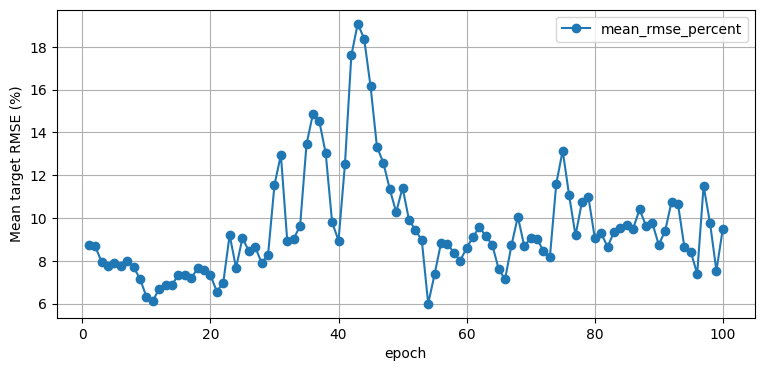

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = (
    OUTPUT_ROOT
    / "formal_paper_protocol_v2_source_only"
    / "source_artifact.pt"
)
transfer_output = (
    OUTPUT_ROOT
    / "diagnostic_paper_protocol_v2_alternating_10ep"
)
adapt_checkpoint = transfer_output / "adapt_last.pt"

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
assert adapt_checkpoint.is_file(), f"Missing adaptation checkpoint: {adapt_checkpoint}"

command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest",
    str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root",
    str(DATA_ROOT),
    "--output",
    str(transfer_output),
    "--source-artifact",
    str(source_artifact),
    "--feature-order",
    "paper_ivt",
    "--source-normalization",
    "source_domain",
    "--transfer-epochs",
    "100",
    "--transfer-lr",
    "0.0001",
    "--batch-size",
    "256",
    "--adversarial-weight",
    "1",
    "--alpha",
    "10",
    "--beta",
    "1",
    "--target-bn-mode",
    "frozen_stats",
    "--adversarial-update",
    "alternating_flipped",
    "--patience",
    "0",
    "--seed",
    "42",
    "--device",
    "cuda",
    "--resume",
]

print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

result = json.loads((transfer_output / "results.json").read_text())

epoch_rows = []
for record in result["adaptation_diagnostics"]:
    training = record["training"]
    epoch_rows.append(
        {
            "epoch": record["epoch"],
            "mean_rmse_percent": training["mean_profile_rmse_percent"],
            "domain_accuracy": training["overall_domain_accuracy"],
            "p_source_given_target": training["mean_p_source_given_target"],
            "target_feature_rms_drift": training["target_feature_rms_drift"],
        }
    )

epochs = pd.DataFrame(epoch_rows)

print("Source-only target results")
display(pd.DataFrame(result["target_source_only"]).T)

print("Target results after the last adaptation epoch")
display(pd.DataFrame(result["target_darm"]).T)

print("Adaptation history")
display(epochs)

print("Diagnostic oracle (not used for checkpoint selection)")
display(pd.DataFrame([result["target_training"]["diagnostic_oracle"]]))

epochs.plot(
    x="epoch",
    y="mean_rmse_percent",
    marker="o",
    figsize=(9, 4),
    ylabel="Mean target RMSE (%)",
    grid=True,
)
plt.show()

## Adaptation instability audit

This is a read-only analysis of the completed 100-epoch diagnostic. It aligns loss values, first-batch gradient norms, domain statistics, feature drift, and post-hoc target RMSE without training or selecting a checkpoint.

Epochs 35-60


,epoch,rmse,total_loss,adversarial_loss,weighted_reconstruction_loss,mmd_loss,adversarial_gradient,reconstruction_gradient,mmd_gradient,total_gradient,domain_accuracy,p_source_given_target,feature_drift
0,35,13.443046,2.088877,1.096379,0.835448,0.157050,29.061155,25.995910,4.114808,11.007707,0.762849,0.369190,1.246943
1,36,14.860231,2.093937,1.133939,0.764761,0.195236,21.508583,43.431281,7.270152,19.909718,0.795408,0.355470,1.344056
2,37,14.517873,2.081851,1.174799,0.697377,0.209675,14.503860,5.899579,6.926874,15.940189,0.845996,0.331066,1.250218
3,38,13.023039,1.914306,1.089436,0.630974,0.193896,5.837444,11.902141,8.291987,4.825093,0.831686,0.362857,1.197889
4,39,9.795360,1.940733,1.170769,0.573725,0.196239,11.408728,2.763616,6.528803,15.346529,0.769392,0.356630,1.465927
5,40,8.944463,2.003913,1.269001,0.523214,0.211697,26.596583,4.884056,1.973582,21.480953,0.816294,0.311008,1.315322
6,41,12.507904,1.915870,1.275185,0.467446,0.173239,22.135110,2.312383,1.401726,23.313783,0.810188,0.320448,1.208895
7,42,17.596271,1.912448,1.263412,0.449599,0.199437,9.646400,11.735885,5.588708,5.796708,0.802099,0.316723,1.354631
8,43,19.078462,2.018875,1.344421,0.432297,0.242156,5.935384,16.430449,8.353385,9.513174,0.813426,0.288005,1.433077
9,44,18.378764,2.015423,1.405242,0.381014,0.229167,11.400047,1.435815,10.829918,3.895560,0.846657,0.275760,1.491106


Lowest and highest target RMSE epochs (diagnostic only)


,epoch,rmse,total_loss,adversarial_loss,weighted_reconstruction_loss,mmd_loss,adversarial_gradient,reconstruction_gradient,mmd_gradient,total_gradient,domain_accuracy,p_source_given_target,feature_drift
53,54,5.994617,1.550140,1.211137,0.196526,0.142477,10.824302,2.340420,1.922296,11.096886,0.746934,0.346873,1.406982
10,11,6.128945,9.118006,1.149006,7.821755,0.147246,24.009765,52.318270,2.033053,29.185568,0.842367,0.338586,0.931140
9,10,6.323408,9.662778,1.021058,8.475029,0.166691,25.459482,112.898828,3.308773,86.291775,0.782288,0.380477,0.892982
20,21,6.558112,4.713443,1.106592,3.494938,0.111913,38.675743,7.955787,5.037672,37.865100,0.733864,0.375543,1.120398
11,12,6.694926,8.457431,1.111316,7.220449,0.125666,23.050083,7.223741,4.481537,28.023485,0.880025,0.352748,0.949068
42,43,19.078462,2.018875,1.344421,0.432297,0.242156,5.935384,16.430449,8.353385,9.513174,0.813426,0.288005,1.433077
43,44,18.378764,2.015423,1.405242,0.381014,0.229167,11.400047,1.435815,10.829918,3.895560,0.846657,0.275760,1.491106
41,42,17.596271,1.912448,1.263412,0.449599,0.199437,9.646400,11.735885,5.588708,5.796708,0.802099,0.316723,1.354631
44,45,16.150401,1.874899,1.299298,0.348546,0.227054,6.613902,12.257743,8.905755,9.416985,0.857040,0.296142,1.391173
35,36,14.860231,2.093937,1.133939,0.764761,0.195236,21.508583,43.431281,7.270152,19.909718,0.795408,0.355470,1.344056


Correlation with target RMSE (post-hoc diagnostic)


,correlation_with_rmse
feature_drift,0.458920
weighted_reconstruction_loss,-0.347196
mmd_loss,0.340166
total_loss,-0.333603
adversarial_loss,0.308303
p_source_given_target,-0.293434
total_gradient,-0.281107
adversarial_gradient,-0.225672
reconstruction_gradient,-0.224551
mmd_gradient,0.176557


Per-profile RMSE around the collapse and recovery


profile,HWFET,LA92,NN,UDDS,US06
epoch,,,,,
10,9.476374,3.897839,4.627590,5.043752,8.571486
11,8.208366,4.158021,4.683779,5.810320,7.784241
40,8.790844,7.832514,7.372144,10.678464,10.048348
43,21.420116,15.561292,15.023788,21.081636,22.305475
44,20.837875,14.892239,14.413542,20.085808,21.664354
45,18.136063,13.061470,12.780218,17.556917,19.217339
50,14.116666,8.744433,8.986459,11.429609,13.807182
54,6.611369,5.026519,4.431405,7.895041,6.008751
55,8.515963,5.708028,5.866899,8.631927,8.150962


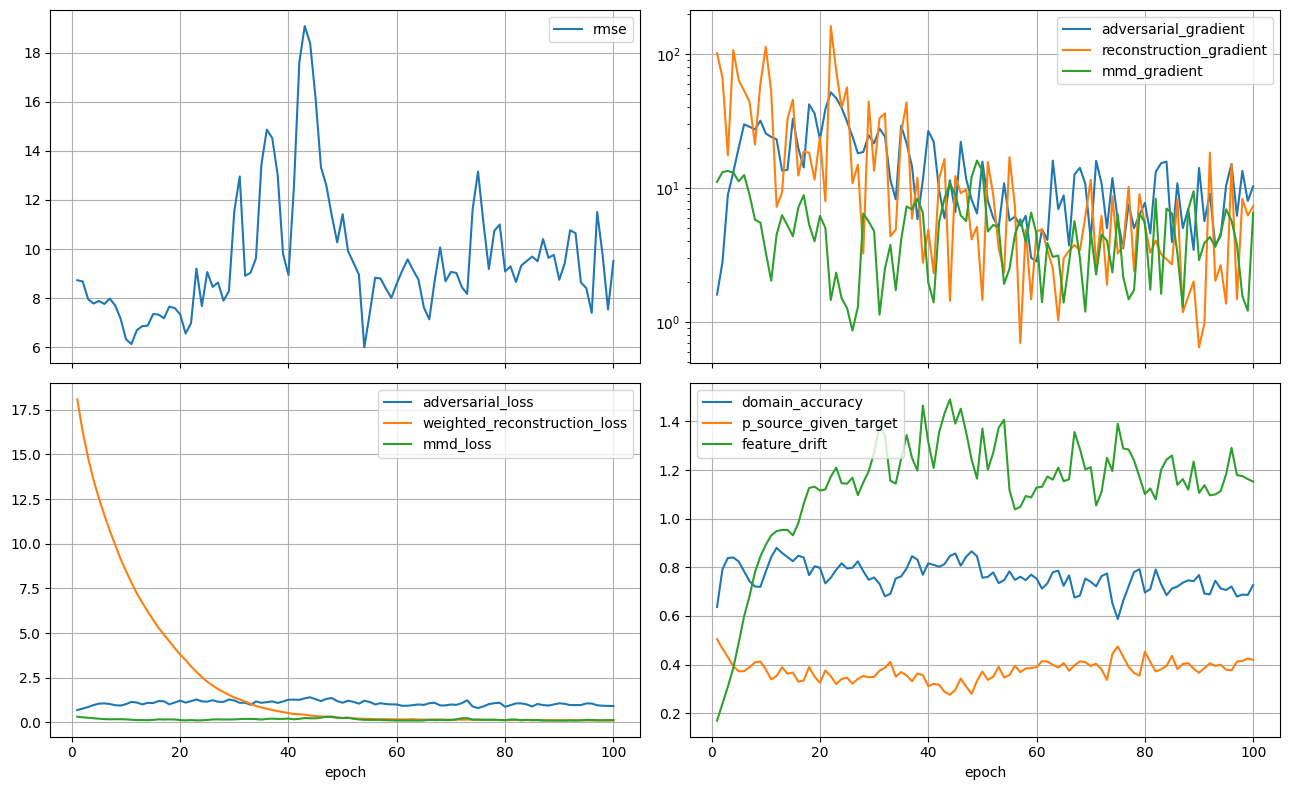

In [ ]:
import json

import matplotlib.pyplot as plt
import pandas as pd

result_path = (
    OUTPUT_ROOT
    / "diagnostic_paper_protocol_v2_alternating_10ep"
    / "results.json"
)
result = json.loads(result_path.read_text())

rows = []
profile_rows = []
for record in result["adaptation_diagnostics"]:
    training = record["training"]
    gradients = training["gradient_l2"]
    rows.append({
        "epoch": record["epoch"],
        "rmse": training["mean_profile_rmse_percent"],
        "total_loss": training["total"],
        "adversarial_loss": training["adversarial"],
        "weighted_reconstruction_loss": 10 * training["reconstruction"],
        "mmd_loss": training["mmd"],
        "adversarial_gradient": gradients["adversarial"],
        "reconstruction_gradient": gradients["reconstruction"],
        "mmd_gradient": gradients["mmd"],
        "total_gradient": gradients["total"],
        "domain_accuracy": training["overall_domain_accuracy"],
        "p_source_given_target": training["mean_p_source_given_target"],
        "feature_drift": training["target_feature_rms_drift"],
    })
    for profile, metrics in training["target_test"].items():
        profile_rows.append({
            "epoch": record["epoch"],
            "profile": profile,
            "rmse": metrics["rmse_percent"],
        })

epochs = pd.DataFrame(rows)
profiles = pd.DataFrame(profile_rows)
assert len(epochs) == 100, f"Expected 100 epochs, found {len(epochs)}"

print("Epochs 35-60")
display(epochs.loc[epochs.epoch.between(35, 60)].reset_index(drop=True))

print("Lowest and highest target RMSE epochs (diagnostic only)")
display(pd.concat([epochs.nsmallest(5, "rmse"), epochs.nlargest(5, "rmse")]))

print("Correlation with target RMSE (post-hoc diagnostic)")
display(
    epochs.drop(columns="epoch")
    .corr()["rmse"]
    .drop("rmse")
    .sort_values(key=abs, ascending=False)
    .to_frame("correlation_with_rmse")
)

print("Per-profile RMSE around the collapse and recovery")
display(
    profiles.loc[profiles.epoch.isin([10, 11, 40, 43, 44, 45, 50, 54, 55, 60, 100])]
    .pivot(index="epoch", columns="profile", values="rmse")
)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
epochs.plot(x="epoch", y="rmse", ax=axes[0, 0], grid=True)
epochs.plot(
    x="epoch",
    y=["adversarial_gradient", "reconstruction_gradient", "mmd_gradient"],
    ax=axes[0, 1],
    logy=True,
    grid=True,
)
epochs.plot(
    x="epoch",
    y=["adversarial_loss", "weighted_reconstruction_loss", "mmd_loss"],
    ax=axes[1, 0],
    grid=True,
)
epochs.plot(
    x="epoch",
    y=["domain_accuracy", "p_source_given_target", "feature_drift"],
    ax=axes[1, 1],
    grid=True,
)
plt.tight_layout()
plt.show()


## Corrected-source joint-GRL comparison

This matched ten-epoch diagnostic uses the same corrected source artifact, seed, data, loss weights, and frozen target-BN statistics as the alternating run. It changes only the adversarial update semantics and records pairwise gradient cosine values.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_paper_protocol_v2_grl_10ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 10 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 1 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update grl_joint --patience 0 --seed 42 --device cuda --resume


,experiment,epoch,mean_rmse_percent,domain_accuracy,p_source_given_target,feature_drift
0,grl_joint,1,9.178340,0.636795,0.503805,0.165222
1,grl_joint,2,8.861609,0.802618,0.460941,0.187605
2,grl_joint,3,8.906163,0.846868,0.418124,0.232123
3,grl_joint,4,9.059060,0.859558,0.368924,0.298959
4,grl_joint,5,8.746123,0.860397,0.326305,0.337184
5,grl_joint,6,8.375992,0.856497,0.295541,0.386335
6,grl_joint,7,8.356187,0.841457,0.281716,0.435297
7,grl_joint,8,8.031839,0.831083,0.275115,0.482590
8,grl_joint,9,8.101704,0.827102,0.274791,0.534222
9,grl_joint,10,7.869790,0.824903,0.281729,0.605862


,epoch,adversarial_vs_reconstruction,adversarial_vs_mmd,reconstruction_vs_mmd
0,1,0.825388,-0.956640,-0.788085
1,2,-0.694859,0.967356,-0.786997
2,3,0.933303,0.995657,0.940254
3,4,0.955802,0.989727,0.946399
4,5,-0.416845,0.988195,-0.517258
5,6,-0.980865,0.979814,-0.993953
6,7,-0.917838,0.983896,-0.862209
7,8,0.901313,0.946181,0.965583
8,9,-0.789671,0.935981,-0.667140
9,10,0.303122,0.985241,0.356679


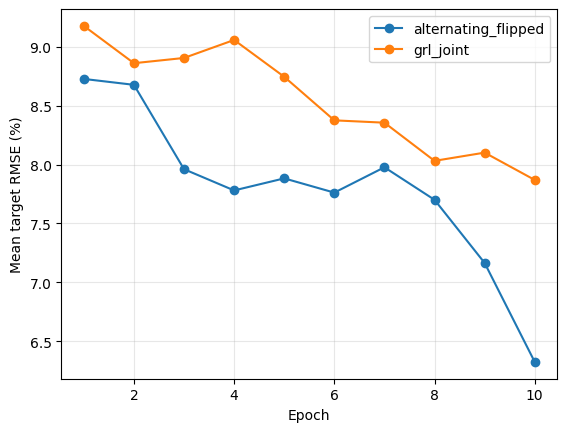

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = (
    OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"
)
grl_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_grl_10ep"
alternating_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_alternating_10ep"
grl_output.mkdir(parents=True, exist_ok=True)

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root", str(DATA_ROOT),
    "--output", str(grl_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--source-normalization", "source_domain",
    "--transfer-epochs", "10",
    "--transfer-lr", "0.0001",
    "--batch-size", "256",
    "--adversarial-weight", "1",
    "--alpha", "10",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--adversarial-update", "grl_joint",
    "--patience", "0",
    "--seed", "42",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

experiments = {
    "grl_joint": json.loads((grl_output / "results.json").read_text()),
    "alternating_flipped": json.loads(
        (alternating_output / "results.json").read_text()
    ),
}
comparison_rows = []
for name, result in experiments.items():
    for record in result["adaptation_diagnostics"][:10]:
        training = record["training"]
        comparison_rows.append({
            "experiment": name,
            "epoch": record["epoch"],
            "mean_rmse_percent": training["mean_profile_rmse_percent"],
            "domain_accuracy": training["overall_domain_accuracy"],
            "p_source_given_target": training["mean_p_source_given_target"],
            "feature_drift": training["target_feature_rms_drift"],
        })

comparison = pd.DataFrame(comparison_rows)
display(comparison)

cosine_rows = []
for record in experiments["grl_joint"]["adaptation_diagnostics"]:
    cosine_rows.append({
        "epoch": record["epoch"],
        **record["training"]["gradient_cosine"],
    })
display(pd.DataFrame(cosine_rows))

for name, group in comparison.groupby("experiment"):
    plt.plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Mean target RMSE (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Corrected-source reconstruction isolation

This matched ten-epoch diagnostic keeps alternating flipped-label adaptation and MMD unchanged, but sets the reconstruction weight to zero. It tests whether the reconstruction gradient stabilizes or disrupts SOC-relevant target features.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_paper_protocol_v2_no_reconstruction_10ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 10 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 1 --alpha 0 --beta 1 --target-bn-mode frozen_stats --adversarial-update alternating_flipped --patience 0 --seed 42 --device cuda --resume


,experiment,epoch,mean_rmse_percent,domain_accuracy,p_source_given_target,mmd_loss,feature_drift
0,no_reconstruction,1,6.738809,0.563629,0.516830,0.199694,1.120002
1,no_reconstruction,2,8.830144,0.565906,0.512589,0.093739,1.449507
2,no_reconstruction,3,8.698561,0.381810,0.515975,0.082301,1.260904
3,no_reconstruction,4,10.868472,0.432533,0.506760,0.068784,1.394718
4,no_reconstruction,5,11.221817,0.510539,0.505427,0.053681,1.269312
5,no_reconstruction,6,11.699400,0.496767,0.508280,0.047554,1.263151
6,no_reconstruction,7,10.703598,0.532394,0.505800,0.045144,1.207442
7,no_reconstruction,8,10.632826,0.531374,0.505806,0.041212,1.199396
8,no_reconstruction,9,10.218189,0.530432,0.503889,0.038841,1.185563
9,no_reconstruction,10,9.806245,0.533230,0.500424,0.038387,1.179064


,rmse_percent,mae_percent,n_windows
LA92,8.930758,6.601275,15368.0
UDDS,14.034560,12.133235,12831.0
US06,9.685351,7.503499,3635.0
HWFET,8.165026,6.071475,5961.0
NN,8.215531,5.984385,13439.0


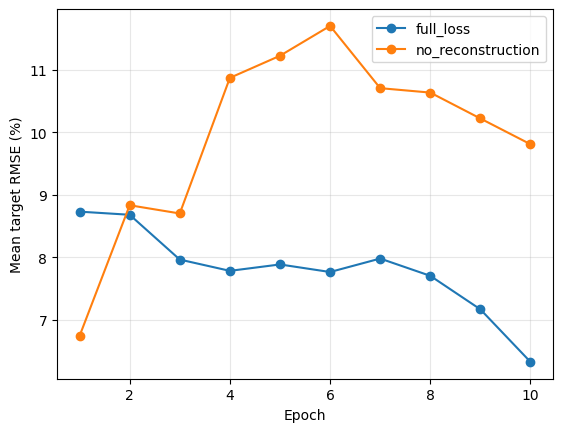

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = (
    OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"
)
no_reconstruction_output = (
    OUTPUT_ROOT / "diagnostic_paper_protocol_v2_no_reconstruction_10ep"
)
full_loss_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_alternating_10ep"
no_reconstruction_output.mkdir(parents=True, exist_ok=True)

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root", str(DATA_ROOT),
    "--output", str(no_reconstruction_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--source-normalization", "source_domain",
    "--transfer-epochs", "10",
    "--transfer-lr", "0.0001",
    "--batch-size", "256",
    "--adversarial-weight", "1",
    "--alpha", "0",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--adversarial-update", "alternating_flipped",
    "--patience", "0",
    "--seed", "42",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

experiments = {
    "no_reconstruction": json.loads(
        (no_reconstruction_output / "results.json").read_text()
    ),
    "full_loss": json.loads((full_loss_output / "results.json").read_text()),
}
rows = []
for name, result in experiments.items():
    for record in result["adaptation_diagnostics"][:10]:
        training = record["training"]
        rows.append({
            "experiment": name,
            "epoch": record["epoch"],
            "mean_rmse_percent": training["mean_profile_rmse_percent"],
            "domain_accuracy": training["overall_domain_accuracy"],
            "p_source_given_target": training["mean_p_source_given_target"],
            "mmd_loss": training["mmd"],
            "feature_drift": training["target_feature_rms_drift"],
        })

comparison = pd.DataFrame(rows)
display(comparison)
display(pd.DataFrame(experiments["no_reconstruction"]["target_darm"]).T)

for name, group in comparison.groupby("experiment"):
    plt.plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Mean target RMSE (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Corrected-source reconstruction and MMD isolation

This matched ten-epoch diagnostic keeps reconstruction and MMD unchanged while removing only the target-encoder adversarial term. The discriminator is still measured, but its loss has zero weight in the target update.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_paper_protocol_v2_reconstruction_mmd_10ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 10 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 0 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update alternating_flipped --patience 0 --seed 42 --device cuda --resume


,experiment,epoch,mean_rmse_percent,mmd_loss,reconstruction_loss,feature_drift
0,reconstruction_mmd,1,8.698390,0.321637,1.808351,0.111874
1,reconstruction_mmd,2,8.625889,0.301679,1.623900,0.164341
2,reconstruction_mmd,3,8.423029,0.285289,1.477157,0.203489
3,reconstruction_mmd,4,8.625433,0.269017,1.354865,0.252979
4,reconstruction_mmd,5,8.449157,0.253179,1.252499,0.281170
5,reconstruction_mmd,6,8.311166,0.235681,1.161149,0.312743
6,reconstruction_mmd,7,8.140876,0.221132,1.077934,0.342715
7,reconstruction_mmd,8,8.100527,0.210533,0.998828,0.367921
8,reconstruction_mmd,9,7.853636,0.196276,0.924528,0.389606
9,reconstruction_mmd,10,7.782893,0.185332,0.856269,0.410638


,rmse_percent,mae_percent,n_windows
LA92,5.209903,3.230862,15368.0
UDDS,6.154592,4.961249,12831.0
US06,10.375852,9.243073,3635.0
HWFET,11.456167,10.289248,5961.0
NN,5.717949,3.442862,13439.0


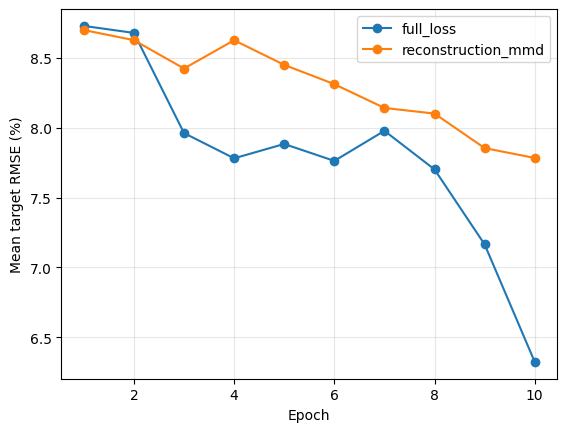

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = (
    OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"
)
reconstruction_mmd_output = (
    OUTPUT_ROOT / "diagnostic_paper_protocol_v2_reconstruction_mmd_10ep"
)
full_loss_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_alternating_10ep"
reconstruction_mmd_output.mkdir(parents=True, exist_ok=True)

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root", str(DATA_ROOT),
    "--output", str(reconstruction_mmd_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--source-normalization", "source_domain",
    "--transfer-epochs", "10",
    "--transfer-lr", "0.0001",
    "--batch-size", "256",
    "--adversarial-weight", "0",
    "--alpha", "10",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--adversarial-update", "alternating_flipped",
    "--patience", "0",
    "--seed", "42",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

experiments = {
    "reconstruction_mmd": json.loads(
        (reconstruction_mmd_output / "results.json").read_text()
    ),
    "full_loss": json.loads((full_loss_output / "results.json").read_text()),
}
rows = []
for name, result in experiments.items():
    for record in result["adaptation_diagnostics"][:10]:
        training = record["training"]
        rows.append({
            "experiment": name,
            "epoch": record["epoch"],
            "mean_rmse_percent": training["mean_profile_rmse_percent"],
            "mmd_loss": training["mmd"],
            "reconstruction_loss": training["reconstruction"],
            "feature_drift": training["target_feature_rms_drift"],
        })

comparison = pd.DataFrame(rows)
display(comparison)
display(pd.DataFrame(experiments["reconstruction_mmd"]["target_darm"]).T)

for name, group in comparison.groupby("experiment"):
    plt.plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Mean target RMSE (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Corrected-source reconstruction and adversarial isolation

This final matched ten-epoch component isolation keeps reconstruction and alternating adversarial alignment unchanged while setting the MMD weight to zero.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_paper_protocol_v2_reconstruction_adversarial_10ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 10 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 1 --alpha 10 --beta 0 --target-bn-mode frozen_stats --adversarial-update alternating_flipped --patience 0 --seed 42 --device cuda --resume


,experiment,epoch,mean_rmse_percent,adversarial_loss,reconstruction_loss,domain_accuracy,p_source_given_target,feature_drift
0,reconstruction_adversarial,1,9.666890,0.693432,1.808499,0.642107,0.502704,0.224528
1,reconstruction_adversarial,2,9.111837,0.804512,1.624518,0.820642,0.452732,0.237828
2,reconstruction_adversarial,3,8.908014,0.944423,1.473625,0.857675,0.400897,0.255833
3,reconstruction_adversarial,4,9.066515,1.102828,1.351376,0.864023,0.353294,0.309331
4,reconstruction_adversarial,5,8.787751,1.201591,1.251178,0.861452,0.329040,0.402804
5,reconstruction_adversarial,6,8.434539,1.179565,1.163954,0.827541,0.340006,0.544264
6,reconstruction_adversarial,7,9.210838,1.082277,1.080896,0.775249,0.372133,0.669056
7,reconstruction_adversarial,8,9.421266,0.933830,1.000684,0.708851,0.422102,0.803064
8,reconstruction_adversarial,9,9.489989,0.926147,0.918848,0.715339,0.419064,0.884635
9,reconstruction_adversarial,10,9.166586,1.060471,0.842969,0.804394,0.368369,0.923970


,rmse_percent,mae_percent,n_windows
LA92,6.420329,3.995964,15368.0
UDDS,7.569665,6.064031,12831.0
US06,11.993597,10.641726,3635.0
HWFET,12.780586,11.292691,5961.0
NN,7.068755,4.256365,13439.0


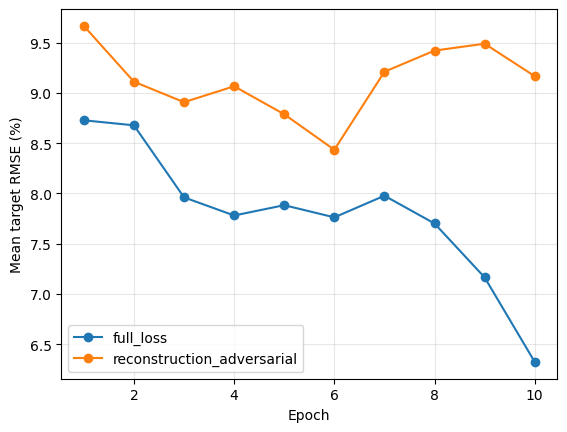

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = (
    OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"
)
reconstruction_adversarial_output = (
    OUTPUT_ROOT / "diagnostic_paper_protocol_v2_reconstruction_adversarial_10ep"
)
full_loss_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_alternating_10ep"
reconstruction_adversarial_output.mkdir(parents=True, exist_ok=True)

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root", str(DATA_ROOT),
    "--output", str(reconstruction_adversarial_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--source-normalization", "source_domain",
    "--transfer-epochs", "10",
    "--transfer-lr", "0.0001",
    "--batch-size", "256",
    "--adversarial-weight", "1",
    "--alpha", "10",
    "--beta", "0",
    "--target-bn-mode", "frozen_stats",
    "--adversarial-update", "alternating_flipped",
    "--patience", "0",
    "--seed", "42",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

experiments = {
    "reconstruction_adversarial": json.loads(
        (reconstruction_adversarial_output / "results.json").read_text()
    ),
    "full_loss": json.loads((full_loss_output / "results.json").read_text()),
}
rows = []
for name, result in experiments.items():
    for record in result["adaptation_diagnostics"][:10]:
        training = record["training"]
        rows.append({
            "experiment": name,
            "epoch": record["epoch"],
            "mean_rmse_percent": training["mean_profile_rmse_percent"],
            "adversarial_loss": training["adversarial"],
            "reconstruction_loss": training["reconstruction"],
            "domain_accuracy": training["overall_domain_accuracy"],
            "p_source_given_target": training["mean_p_source_given_target"],
            "feature_drift": training["target_feature_rms_drift"],
        })

comparison = pd.DataFrame(rows)
display(comparison)
display(pd.DataFrame(experiments["reconstruction_adversarial"]["target_darm"]).T)

for name, group in comparison.groupby("experiment"):
    plt.plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Mean target RMSE (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Adaptation gradient-balance audit

This read-only diagnostic tests whether reconstruction loses control as its gradient decays relative to adversarial and MMD gradients. Target RMSE remains post-hoc and is not used for checkpoint selection.

Milestones and collapse window


,epoch,rmse,adversarial_gradient,reconstruction_gradient,mmd_gradient,total_gradient,adversarial_to_reconstruction,alignment_to_reconstruction,gradient_cancellation_ratio,feature_drift,next_epoch_rmse_change
0,1,8.727864,1.602298,101.213457,11.075605,93.939841,0.015831,0.125259,0.824820,0.169153,-0.050030
1,2,8.677834,2.790979,66.585135,13.132741,81.249930,0.041916,0.239148,0.984742,0.239022,-0.716837
2,5,7.883003,19.982026,63.618571,11.201471,34.393722,0.314091,0.490163,0.362795,0.489437,-0.121076
3,10,6.323408,25.459482,112.898828,3.308773,86.291775,0.225507,0.254814,0.609117,0.892982,-0.194463
4,20,7.339477,23.038032,24.049052,6.177574,6.514987,0.957960,1.214834,0.122313,1.115885,-0.781365
5,30,11.548758,21.538705,13.441080,4.768434,14.545177,1.602453,1.957219,0.365933,1.271220,1.404316
6,35,13.443046,29.061155,25.995910,4.114808,11.007707,1.117913,1.276199,0.186029,1.246943,1.417184
7,40,8.944463,26.596583,4.884056,1.973582,21.480953,5.445593,5.849680,0.642100,1.315322,3.563441
8,41,12.507904,22.135110,2.312383,1.401726,23.313783,9.572422,10.178605,0.901914,1.208895,5.088367
9,42,17.596271,9.646400,11.735885,5.588708,5.796708,0.821958,1.298164,0.214924,1.354631,1.482191


First adversarial/reconstruction gradient crossover


,epoch,rmse,adversarial_gradient,reconstruction_gradient,mmd_gradient,total_gradient,adversarial_to_reconstruction,alignment_to_reconstruction,gradient_cancellation_ratio,feature_drift,next_epoch_rmse_change
7,8,7.700910,27.321630,21.075408,5.792439,29.112420,1.296375,1.571218,0.537234,0.779643,-0.536565
11,12,6.694926,23.050083,7.223741,4.481537,28.023485,3.190879,3.811269,0.806307,0.949068,0.166128
12,13,6.861055,13.451241,9.236787,6.259254,18.349529,1.456268,2.133913,0.633895,0.953981,0.016264
15,16,7.332993,19.844840,12.383158,7.126268,38.359819,1.602567,2.178048,0.974731,0.981346,-0.155095
17,18,7.655565,42.023123,18.316779,5.336235,31.846533,2.294242,2.585572,0.484903,1.126601,-0.063367
18,19,7.592199,36.023835,11.510997,3.999211,50.648347,3.129515,3.476940,0.982813,1.132033,-0.252722
20,21,6.558112,38.675743,7.955787,5.037672,37.865100,4.861335,5.494543,0.732837,1.120398,0.417449
25,26,8.457452,24.277102,10.843180,0.863343,15.223198,2.238928,2.318549,0.423059,1.168705,0.178625
26,27,8.636077,18.131737,14.923930,1.285823,33.843389,1.214944,1.301102,0.985496,1.096997,-0.739888
27,28,7.896189,18.531509,3.240819,6.442570,24.192601,5.718156,7.706100,0.857441,1.148929,0.388655


Post-hoc correlations


,rmse,next_epoch_rmse_change
adversarial_to_reconstruction,0.050152,0.066848
alignment_to_reconstruction,0.111326,-0.024060
gradient_cancellation_ratio,-0.229589,0.227703
feature_drift,0.458920,-0.038681


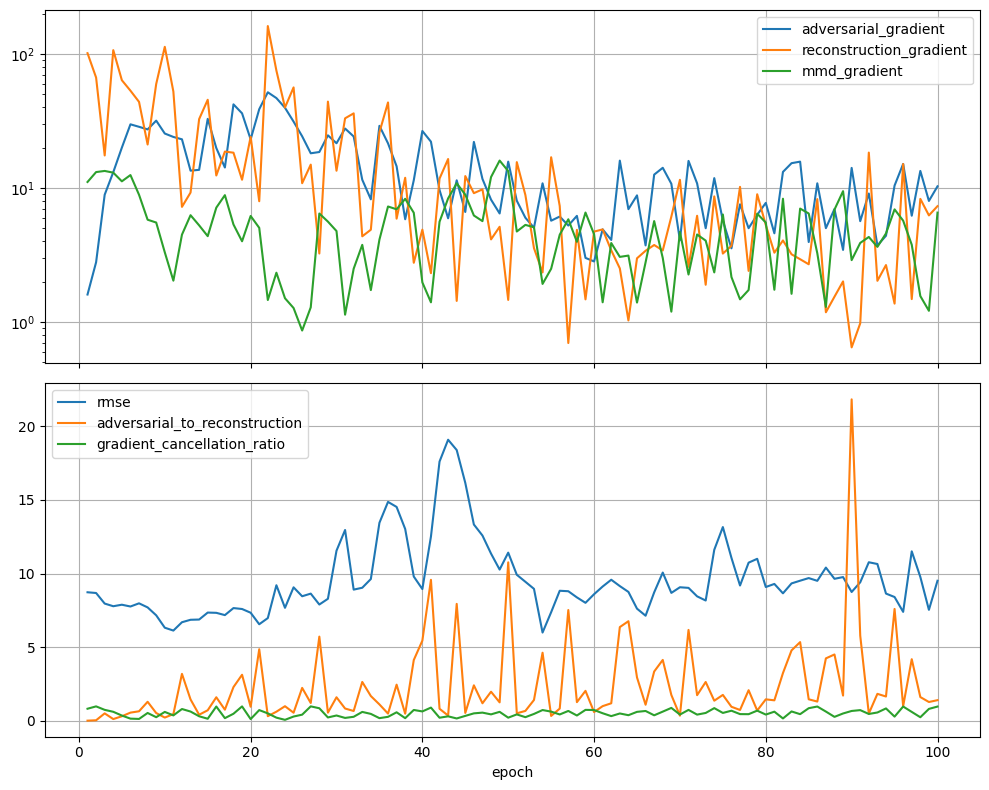

In [ ]:
import json

import matplotlib.pyplot as plt
import pandas as pd

result_path = (
    OUTPUT_ROOT
    / "diagnostic_paper_protocol_v2_alternating_10ep"
    / "results.json"
)
result = json.loads(result_path.read_text())

rows = []
for record in result["adaptation_diagnostics"]:
    training = record["training"]
    gradients = training["gradient_l2"]
    component_sum = (
        gradients["adversarial"]
        + gradients["reconstruction"]
        + gradients["mmd"]
    )
    rows.append({
        "epoch": record["epoch"],
        "rmse": training["mean_profile_rmse_percent"],
        "adversarial_gradient": gradients["adversarial"],
        "reconstruction_gradient": gradients["reconstruction"],
        "mmd_gradient": gradients["mmd"],
        "total_gradient": gradients["total"],
        "adversarial_to_reconstruction": (
            gradients["adversarial"] / gradients["reconstruction"]
            if gradients["reconstruction"] else float("inf")
        ),
        "alignment_to_reconstruction": (
            (gradients["adversarial"] + gradients["mmd"])
            / gradients["reconstruction"]
            if gradients["reconstruction"] else float("inf")
        ),
        "gradient_cancellation_ratio": (
            gradients["total"] / component_sum if component_sum else 0.0
        ),
        "feature_drift": training["target_feature_rms_drift"],
    })

balance = pd.DataFrame(rows)
balance["next_epoch_rmse_change"] = balance.rmse.shift(-1) - balance.rmse

print("Milestones and collapse window")
display(
    balance.loc[
        balance.epoch.isin([1, 2, 5, 10, 20, 30, 35, 40, 41, 42, 43, 44, 45, 50, 54, 60, 80, 100])
    ].reset_index(drop=True)
)

print("First adversarial/reconstruction gradient crossover")
display(balance.loc[balance.adversarial_to_reconstruction >= 1].head(10))

print("Post-hoc correlations")
display(
    balance.drop(columns="epoch")
    .corr()[["rmse", "next_epoch_rmse_change"]]
    .loc[[
        "adversarial_to_reconstruction",
        "alignment_to_reconstruction",
        "gradient_cancellation_ratio",
        "feature_drift",
    ]]
)

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
balance.plot(
    x="epoch",
    y=["adversarial_gradient", "reconstruction_gradient", "mmd_gradient"],
    logy=True,
    grid=True,
    ax=axes[0],
)
balance.plot(
    x="epoch",
    y=["rmse", "adversarial_to_reconstruction", "gradient_cancellation_ratio"],
    grid=True,
    ax=axes[1],
)
plt.tight_layout()
plt.show()


## Corrected-source continuous 30-epoch check

This run keeps every model and loss setting unchanged but starts in a new output directory and trains continuously through epoch 30. It isolates the effect of the historical resume-time RNG resets.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_paper_protocol_v2_continuous_30ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 30 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 1 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update alternating_flipped --patience 0 --seed 42 --device cuda --resume


,experiment,epoch,mean_rmse_percent,domain_accuracy,p_source_given_target,feature_drift
0,continuous,1,9.419927,0.639721,0.503629,0.262765
1,continuous,2,8.637451,0.790045,0.464495,0.301018
4,continuous,5,7.772825,0.792267,0.375979,0.480098
9,continuous,10,7.314573,0.804623,0.379453,0.917925
10,continuous,11,6.661715,0.864458,0.344845,0.918182
14,continuous,15,7.118217,0.791286,0.376000,0.998614
19,continuous,20,6.465530,0.739375,0.372883,1.103574
24,continuous,25,7.218384,0.810556,0.357941,1.284315
29,continuous,30,10.088637,0.757005,0.374625,1.267088
30,historical_segmented,1,8.727864,0.637154,0.504478,0.169153


,rmse_percent,mae_percent,n_windows
LA92,8.942122,6.065232,15368.0
UDDS,11.351473,9.378043,12831.0
US06,11.755263,8.425646,3635.0
HWFET,10.232126,7.051391,5961.0
NN,8.162203,5.220444,13439.0


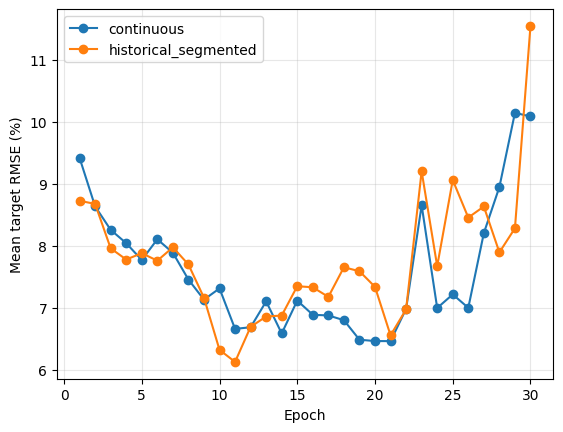

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = (
    OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"
)
continuous_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_continuous_30ep"
segmented_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_alternating_10ep"
continuous_output.mkdir(parents=True, exist_ok=True)

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root", str(DATA_ROOT),
    "--output", str(continuous_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--source-normalization", "source_domain",
    "--transfer-epochs", "30",
    "--transfer-lr", "0.0001",
    "--batch-size", "256",
    "--adversarial-weight", "1",
    "--alpha", "10",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--adversarial-update", "alternating_flipped",
    "--patience", "0",
    "--seed", "42",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

experiments = {
    "continuous": json.loads((continuous_output / "results.json").read_text()),
    "historical_segmented": json.loads(
        (segmented_output / "results.json").read_text()
    ),
}
rows = []
for name, result in experiments.items():
    for record in result["adaptation_diagnostics"][:30]:
        training = record["training"]
        rows.append({
            "experiment": name,
            "epoch": record["epoch"],
            "mean_rmse_percent": training["mean_profile_rmse_percent"],
            "domain_accuracy": training["overall_domain_accuracy"],
            "p_source_given_target": training["mean_p_source_given_target"],
            "feature_drift": training["target_feature_rms_drift"],
        })

comparison = pd.DataFrame(rows)
display(comparison.loc[comparison.epoch.isin([1, 2, 5, 10, 11, 15, 20, 25, 30])])
display(pd.DataFrame(experiments["continuous"]["target_darm"]).T)

for name, group in comparison.groupby("experiment"):
    plt.plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Mean target RMSE (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## DANN adversarial-weight schedule diagnostic

This matched 30-epoch run changes only the target encoder adversarial weight. The discriminator still trains at full strength, while the target adversarial weight follows the original DANN 0-to-1 schedule.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_paper_protocol_v2_dann_schedule_30ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 30 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 1 --adversarial-schedule dann --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update alternating_flipped --patience 0 --seed 42 --device cuda --resume


,experiment,epoch,mean_rmse_percent,adversarial_weight,domain_accuracy,p_source_given_target,feature_drift
0,constant,1,9.419927,1.000000,0.639721,0.503629,0.262765
1,constant,2,8.637451,1.000000,0.790045,0.464495,0.301018
4,constant,5,7.772825,1.000000,0.792267,0.375979,0.480098
9,constant,10,7.314573,1.000000,0.804623,0.379453,0.917925
14,constant,15,7.118217,1.000000,0.791286,0.376000,0.998614
19,constant,20,6.465530,1.000000,0.739375,0.372883,1.103574
24,constant,25,7.218384,1.000000,0.810556,0.357941,1.284315
29,constant,30,10.088637,1.000000,0.757005,0.374625,1.267088
30,dann,1,9.859783,0.080667,0.642758,0.502593,0.251025
31,dann,2,9.511797,0.242373,0.802891,0.457319,0.273421


,rmse_percent,mae_percent,n_windows
LA92,7.500743,5.214612,15368.0
UDDS,11.751650,10.388420,12831.0
US06,8.285141,6.094128,3635.0
HWFET,6.558619,4.625039,5961.0
NN,6.552091,4.277308,13439.0


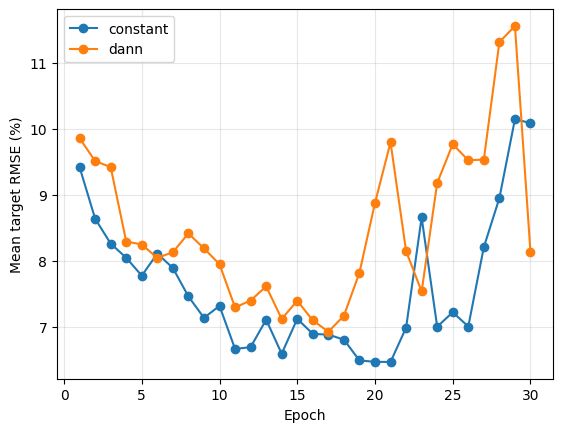

In [ ]:
dann_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_dann_schedule_30ep"
dann_output.mkdir(parents=True, exist_ok=True)

command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root", str(DATA_ROOT),
    "--output", str(dann_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--source-normalization", "source_domain",
    "--transfer-epochs", "30",
    "--transfer-lr", "0.0001",
    "--batch-size", "256",
    "--adversarial-weight", "1",
    "--adversarial-schedule", "dann",
    "--alpha", "10",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--adversarial-update", "alternating_flipped",
    "--patience", "0",
    "--seed", "42",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

scheduled = json.loads((dann_output / "results.json").read_text())
rows = []
for name, result in {"constant": experiments["continuous"], "dann": scheduled}.items():
    for record in result["adaptation_diagnostics"]:
        training = record["training"]
        rows.append({
            "experiment": name,
            "epoch": record["epoch"],
            "mean_rmse_percent": training["mean_profile_rmse_percent"],
            "adversarial_weight": training.get("adversarial_weight", 1.0),
            "domain_accuracy": training["overall_domain_accuracy"],
            "p_source_given_target": training["mean_p_source_given_target"],
            "feature_drift": training["target_feature_rms_drift"],
        })

schedule_comparison = pd.DataFrame(rows)
display(schedule_comparison.loc[schedule_comparison.epoch.isin([1, 2, 5, 10, 15, 20, 25, 30])])
display(pd.DataFrame(scheduled["target_darm"]).T)

for name, group in schedule_comparison.groupby("experiment"):
    plt.plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Mean target RMSE (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Continuous 30-epoch reconstruction + MMD control

This run removes only the target encoder adversarial gradient. It tests whether the late oscillation remains under reconstruction and MMD alone.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_paper_protocol_v2_reconstruction_mmd_30ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 30 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 0 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update alternating_flipped --patience 0 --seed 42 --device cuda --resume


,experiment,epoch,mean_rmse_percent,feature_drift,mmd_loss,reconstruction_loss
0,full,1,9.419927,0.262765,0.312765,1.808963
1,full,2,8.637451,0.301018,0.284316,1.626268
4,full,5,7.772825,0.480098,0.195560,1.255203
9,full,10,7.314573,0.917925,0.176922,0.837994
14,full,15,7.118217,0.998614,0.132995,0.563799
19,full,20,6.465530,1.103574,0.107373,0.363038
24,full,25,7.218384,1.284315,0.136449,0.224046
29,full,30,10.088637,1.267088,0.133239,0.137664
30,reconstruction_mmd,1,9.087723,0.149001,0.326573,1.808788
31,reconstruction_mmd,2,8.500129,0.173563,0.301578,1.622966


,rmse_percent,mae_percent,n_windows
LA92,4.613302,2.643264,15368.0
UDDS,6.442960,4.788422,12831.0
US06,7.476094,5.775846,3635.0
HWFET,7.469468,6.099199,5961.0
NN,4.631042,2.630543,13439.0


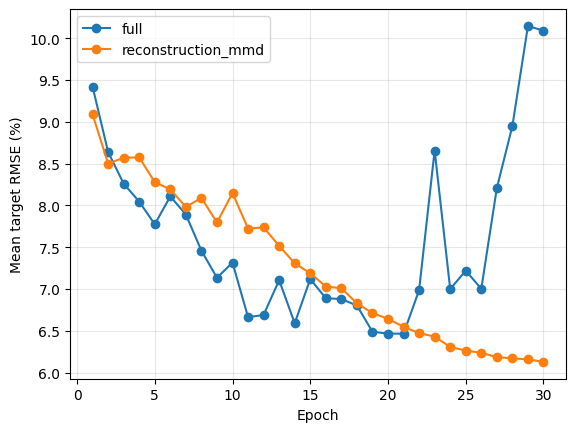

In [ ]:
source_artifact = OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"
baseline_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_continuous_30ep"
control_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_reconstruction_mmd_30ep"
control_output.mkdir(parents=True, exist_ok=True)

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
assert (baseline_output / "results.json").is_file(), "Run the continuous baseline first"
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root", str(DATA_ROOT),
    "--output", str(control_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--source-normalization", "source_domain",
    "--transfer-epochs", "30",
    "--transfer-lr", "0.0001",
    "--batch-size", "256",
    "--adversarial-weight", "0",
    "--alpha", "10",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--adversarial-update", "alternating_flipped",
    "--patience", "0",
    "--seed", "42",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

controls = {
    "full": json.loads((baseline_output / "results.json").read_text()),
    "reconstruction_mmd": json.loads((control_output / "results.json").read_text()),
}
rows = []
for name, result in controls.items():
    for record in result["adaptation_diagnostics"]:
        training = record["training"]
        rows.append({
            "experiment": name,
            "epoch": record["epoch"],
            "mean_rmse_percent": training["mean_profile_rmse_percent"],
            "feature_drift": training["target_feature_rms_drift"],
            "mmd_loss": training["mmd"],
            "reconstruction_loss": training["reconstruction"],
        })

control_comparison = pd.DataFrame(rows)
display(control_comparison.loc[control_comparison.epoch.isin([1, 2, 5, 10, 15, 20, 25, 30])])
display(pd.DataFrame(controls["reconstruction_mmd"]["target_darm"]).T)

for name, group in control_comparison.groupby("experiment"):
    plt.plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Mean target RMSE (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Continuous 30-epoch joint-GRL control

This run keeps all three paper losses at their stated weights and changes only adversarial update semantics from alternating flipped labels to a joint gradient-reversal update.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_paper_protocol_v2_grl_30ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 30 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 1 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update grl_joint --patience 0 --seed 42 --device cuda --resume


,experiment,epoch,mean_rmse_percent,feature_drift,domain_accuracy,p_source_given_target
0,alternating,1,9.419927,0.262765,0.639721,0.503629
1,alternating,2,8.637451,0.301018,0.790045,0.464495
4,alternating,5,7.772825,0.480098,0.792267,0.375979
9,alternating,10,7.314573,0.917925,0.804623,0.379453
14,alternating,15,7.118217,0.998614,0.791286,0.376000
19,alternating,20,6.465530,1.103574,0.739375,0.372883
24,alternating,25,7.218384,1.284315,0.810556,0.357941
29,alternating,30,10.088637,1.267088,0.757005,0.374625
30,grl_joint,1,8.538916,0.117428,0.635709,0.504205
31,grl_joint,2,8.060578,0.176789,0.787464,0.460710


,rmse_percent,mae_percent,n_windows
LA92,5.130964,3.002979,15368.0
UDDS,7.218733,5.385208,12831.0
US06,8.670790,6.373847,3635.0
HWFET,8.009424,6.165504,5961.0
NN,5.426694,3.157786,13439.0


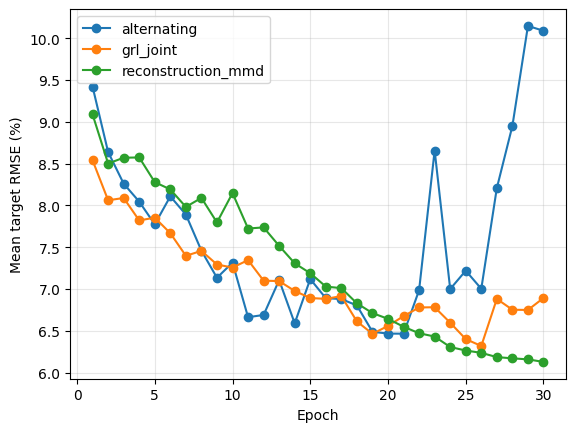

In [ ]:
source_artifact = OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"
alternating_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_continuous_30ep"
no_adversarial_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_reconstruction_mmd_30ep"
grl_output = OUTPUT_ROOT / "diagnostic_paper_protocol_v2_grl_30ep"
grl_output.mkdir(parents=True, exist_ok=True)

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
assert (alternating_output / "results.json").is_file(), "Run the continuous baseline first"
assert (no_adversarial_output / "results.json").is_file(), "Run the no-adversarial control first"
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root", str(DATA_ROOT),
    "--output", str(grl_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--source-normalization", "source_domain",
    "--transfer-epochs", "30",
    "--transfer-lr", "0.0001",
    "--batch-size", "256",
    "--adversarial-weight", "1",
    "--alpha", "10",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--adversarial-update", "grl_joint",
    "--patience", "0",
    "--seed", "42",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

grl_controls = {
    "alternating": json.loads((alternating_output / "results.json").read_text()),
    "grl_joint": json.loads((grl_output / "results.json").read_text()),
    "reconstruction_mmd": json.loads((no_adversarial_output / "results.json").read_text()),
}
rows = []
for name, result in grl_controls.items():
    for record in result["adaptation_diagnostics"]:
        training = record["training"]
        rows.append({
            "experiment": name,
            "epoch": record["epoch"],
            "mean_rmse_percent": training["mean_profile_rmse_percent"],
            "feature_drift": training["target_feature_rms_drift"],
            "domain_accuracy": training["overall_domain_accuracy"],
            "p_source_given_target": training["mean_p_source_given_target"],
        })

grl_comparison = pd.DataFrame(rows)
display(grl_comparison.loc[grl_comparison.epoch.isin([1, 2, 5, 10, 15, 20, 25, 30])])
display(pd.DataFrame(grl_controls["grl_joint"]["target_darm"]).T)

for name, group in grl_comparison.groupby("experiment"):
    plt.plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Mean target RMSE (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Formal 50-epoch transfer run

This run uses the stable paper-aligned configuration: joint GRL, reconstruction, MMD, and frozen target BN statistics. Target labels are used only for post-epoch reporting.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_grl_frozen_stats_50ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 50 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 1 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update grl_joint --patience 0 --seed 42 --device cuda --resume
Source-only mean RMSE: 8.7244%


,epoch,mean_rmse_percent,improvement_vs_source_only,domain_accuracy,p_source_given_target,feature_drift
0,1,8.308454,0.415933,0.636267,0.503632,0.142119
1,2,7.880317,0.844070,0.788036,0.460865,0.221706
4,5,7.258553,1.465834,0.849554,0.334226,0.386945
9,10,7.196920,1.527467,0.823533,0.286367,0.628244
19,20,6.478186,2.246201,0.891690,0.197981,0.795943
29,30,6.608032,2.116355,0.874435,0.221550,1.107975
39,40,7.125703,1.598684,0.878503,0.213199,1.114966
49,50,7.438789,1.285598,0.807831,0.276560,1.049451
59,60,9.265596,-0.541209,0.708127,0.369016,1.176315
69,70,9.375933,-0.651546,0.624178,0.446068,1.179104


,rmse_percent,mae_percent,n_windows
LA92,8.485871,4.963781,15368.0
UDDS,13.037370,10.410501,12831.0
US06,10.150662,7.145937,3635.0
HWFET,9.578439,6.892259,5961.0
NN,8.115645,4.443888,13439.0


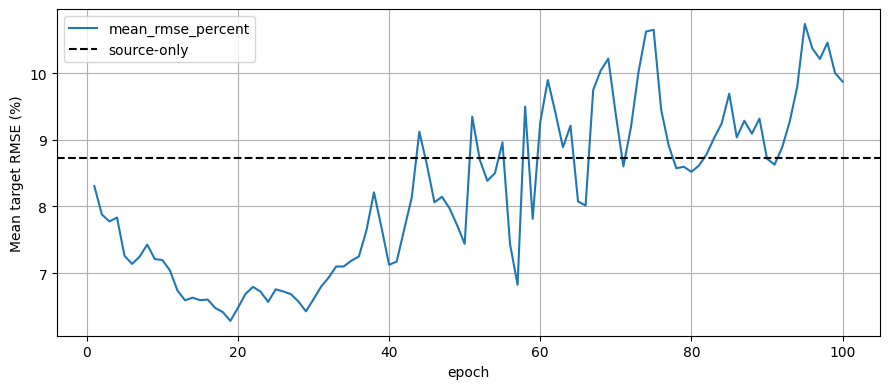

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"
formal_output = OUTPUT_ROOT / "formal_paper_protocol_v2_grl_frozen_stats_50ep"
formal_output.mkdir(parents=True, exist_ok=True)

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root", str(DATA_ROOT),
    "--output", str(formal_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--source-normalization", "source_domain",
    "--transfer-epochs", "50",
    "--transfer-lr", "0.0001",
    "--batch-size", "256",
    "--adversarial-weight", "1",
    "--alpha", "10",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--adversarial-update", "grl_joint",
    "--patience", "0",
    "--seed", "42",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

result = json.loads((formal_output / "results.json").read_text())
assert result["run_mode"] == "formal"
assert result["target_bn_mode"] == "frozen_stats"
assert result["adversarial_update"] == "grl_joint"

source_only_mean = pd.DataFrame(result["target_source_only"]).T.rmse_percent.mean()
epochs = pd.DataFrame([
    {
        "epoch": record["epoch"],
        "mean_rmse_percent": record["training"]["mean_profile_rmse_percent"],
        "improvement_vs_source_only": source_only_mean - record["training"]["mean_profile_rmse_percent"],
        "domain_accuracy": record["training"]["overall_domain_accuracy"],
        "p_source_given_target": record["training"]["mean_p_source_given_target"],
        "feature_drift": record["training"]["target_feature_rms_drift"],
    }
    for record in result["adaptation_diagnostics"]
])

print(f"Source-only mean RMSE: {source_only_mean:.4f}%")
display(epochs.loc[epochs.epoch.isin([1, 2, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])])
display(pd.DataFrame(result["target_darm"]).T)
epochs.plot(x="epoch", y="mean_rmse_percent", figsize=(9, 4), grid=True)
plt.axhline(source_only_mean, color="black", linestyle="--", label="source-only")
plt.ylabel("Mean target RMSE (%)")
plt.legend()
plt.tight_layout()
plt.show()


## Reduced target-encoder GRL strength

This fresh 50-epoch run keeps the discriminator loss at full strength while scaling only the reversed gradient reaching the target encoder to 0.1.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_grl_strength_0p1_50ep --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 100 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 1 --grl-strength 0.1 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update grl_joint --patience 0 --seed 42 --device cuda --resume


,epoch,mean_rmse_percent,improvement_vs_source_only,domain_accuracy,p_source_given_target,feature_drift
0,1,8.351652,0.372735,0.641122,0.502025,0.152288
1,2,8.650916,0.073471,0.781251,0.460727,0.194365
4,5,8.285185,0.439202,0.866051,0.315742,0.300054
9,10,7.678507,1.045879,0.894765,0.196395,0.480454
19,20,6.604989,2.119398,0.980351,0.048395,0.663418
29,30,6.193862,2.530525,0.995084,0.013931,0.801798
39,40,6.316942,2.407445,0.997210,0.007932,0.886586
49,50,6.455377,2.269010,0.998326,0.005775,0.929640
59,60,6.719732,2.004655,0.998209,0.005286,0.968894
69,70,7.032714,1.691673,0.997849,0.005600,1.001906


,rmse_percent,mae_percent,n_windows
LA92,6.496778,4.036801,15368.0
UDDS,9.176743,7.368080,12831.0
US06,8.963968,6.620245,3635.0
HWFET,9.147049,7.019332,5961.0
NN,6.263654,3.714338,13439.0


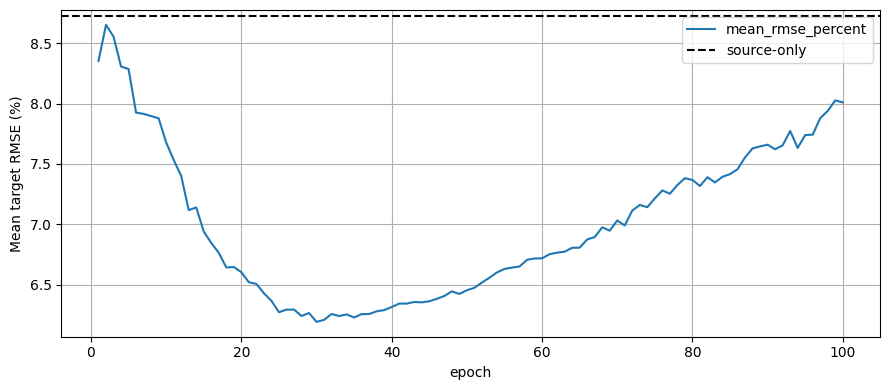

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"
weak_grl_output = OUTPUT_ROOT / "formal_paper_protocol_v2_grl_strength_0p1_50ep"
weak_grl_output.mkdir(parents=True, exist_ok=True)

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root", str(DATA_ROOT),
    "--output", str(weak_grl_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--source-normalization", "source_domain",
    "--transfer-epochs", "500",
    "--transfer-lr", "0.0001",
    "--batch-size", "256",
    "--adversarial-weight", "1",
    "--grl-strength", "0.1",
    "--alpha", "10",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--adversarial-update", "grl_joint",
    "--patience", "0",
    "--seed", "42",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

weak_result = json.loads((weak_grl_output / "results.json").read_text())
assert weak_result["grl_strength"] == 0.1
source_only_mean = pd.DataFrame(weak_result["target_source_only"]).T.rmse_percent.mean()
weak_epochs = pd.DataFrame([
    {
        "epoch": record["epoch"],
        "mean_rmse_percent": record["training"]["mean_profile_rmse_percent"],
        "improvement_vs_source_only": source_only_mean - record["training"]["mean_profile_rmse_percent"],
        "domain_accuracy": record["training"]["overall_domain_accuracy"],
        "p_source_given_target": record["training"]["mean_p_source_given_target"],
        "feature_drift": record["training"]["target_feature_rms_drift"],
    }
    for record in weak_result["adaptation_diagnostics"]
])
display(weak_epochs.loc[weak_epochs.epoch.isin([1, 2, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])])
display(pd.DataFrame(weak_result["target_darm"]).T)
weak_epochs.plot(x="epoch", y="mean_rmse_percent", figsize=(9, 4), grid=True)
plt.axhline(source_only_mean, color="black", linestyle="--", label="source-only")
plt.ylabel("Mean target RMSE (%)")
plt.legend()
plt.tight_layout()
plt.show()


## Paper early-stopping protocol

This fresh run uses the paper's 100 transfer epochs and patience of 20. Early stopping monitors only the unlabeled adaptation total-loss proxy; target SOC labels remain post-hoc diagnostics.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_grl_0p1_patience20 --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --feature-order paper_ivt --source-normalization source_domain --transfer-epochs 100 --transfer-lr 0.0001 --batch-size 256 --adversarial-weight 1 --grl-strength 0.1 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update grl_joint --patience 20 --seed 42 --device cuda --resume
Stopped at epoch: 100
Source-only mean RMSE: 8.7244%
Post-hoc diagnostic oracle: {'used_for_training_or_selection': False, 'epoch': 30, 'mean_pro

,epoch,mean_rmse_percent,improvement_vs_source_only,total_loss,domain_accuracy,p_source_given_target,feature_drift
0,1,9.697296,-0.972909,19.061381,0.648053,0.501269,0.240605
1,2,9.578863,-0.854476,17.130402,0.812531,0.454105,0.271952
4,5,8.601699,0.122687,13.213614,0.867594,0.309942,0.326838
9,10,8.183563,0.540824,8.973308,0.886717,0.194400,0.443462
19,20,6.840556,1.883831,4.021654,0.981548,0.054135,0.617717
29,30,6.174784,2.549603,1.551666,0.994891,0.015119,0.774667
39,40,6.258142,2.466245,0.583019,0.997042,0.008239,0.867889
49,50,6.484389,2.239998,0.281963,0.998184,0.005834,0.942905
59,60,6.739370,1.985017,0.217245,0.998432,0.005392,0.955795
69,70,6.990747,1.733640,0.176538,0.997123,0.007058,0.993800


,rmse_percent,mae_percent,n_windows
LA92,6.405281,4.101773,15368.0
UDDS,9.218513,7.456305,12831.0
US06,8.546328,6.304811,3635.0
HWFET,8.065054,6.163023,5961.0
NN,6.216945,3.827052,13439.0


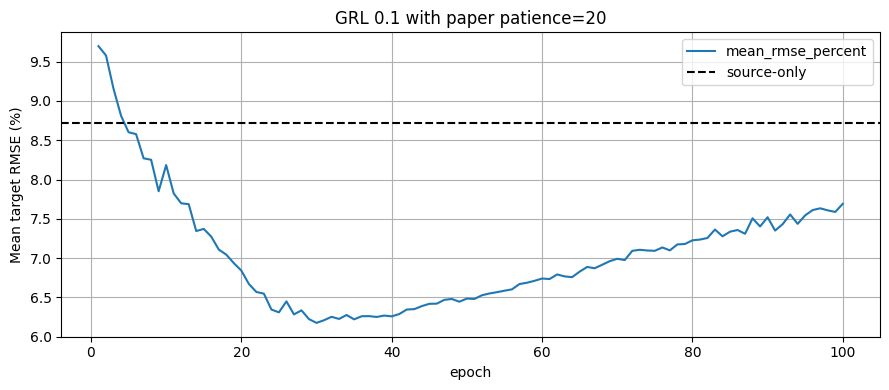

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"
patience_output = OUTPUT_ROOT / "formal_paper_protocol_v2_grl_0p1_patience20"
patience_output.mkdir(parents=True, exist_ok=True)

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"),
    "--manifest", str(REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"),
    "--data-root", str(DATA_ROOT),
    "--output", str(patience_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--source-normalization", "source_domain",
    "--transfer-epochs", "100",
    "--transfer-lr", "0.0001",
    "--batch-size", "256",
    "--adversarial-weight", "1",
    "--grl-strength", "0.1",
    "--alpha", "10",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--adversarial-update", "grl_joint",
    "--patience", "20",
    "--seed", "42",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

patience_result = json.loads((patience_output / "results.json").read_text())
assert patience_result["run_mode"] == "formal"
assert patience_result["grl_strength"] == 0.1
assert patience_result["target_bn_mode"] == "frozen_stats"

source_only_mean = pd.DataFrame(patience_result["target_source_only"]).T.rmse_percent.mean()
patience_epochs = pd.DataFrame([
    {
        "epoch": record["epoch"],
        "mean_rmse_percent": record["training"]["mean_profile_rmse_percent"],
        "improvement_vs_source_only": source_only_mean - record["training"]["mean_profile_rmse_percent"],
        "total_loss": record["training"]["total"],
        "domain_accuracy": record["training"]["overall_domain_accuracy"],
        "p_source_given_target": record["training"]["mean_p_source_given_target"],
        "feature_drift": record["training"]["target_feature_rms_drift"],
    }
    for record in patience_result["adaptation_diagnostics"]
])

stopped_epoch = int(patience_result["target_training"]["epoch"])
print(f"Stopped at epoch: {stopped_epoch}")
print(f"Source-only mean RMSE: {source_only_mean:.4f}%")
print("Post-hoc diagnostic oracle:", patience_result["target_training"]["diagnostic_oracle"])
display(patience_epochs.loc[patience_epochs.epoch.isin([1, 2, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, stopped_epoch])])
display(pd.DataFrame(patience_result["target_darm"]).T)

patience_epochs.plot(x="epoch", y="mean_rmse_percent", figsize=(9, 4), grid=True)
plt.axhline(source_only_mean, color="black", linestyle="--", label="source-only")
plt.ylabel("Mean target RMSE (%)")
plt.title("GRL 0.1 with paper patience=20")
plt.legend()
plt.tight_layout()
plt.show()


## Full six-condition temperature suite

This reuses the corrected 25 C source artifact, resumes interrupted target runs, and writes a Table V-style CSV with source-only, supervised fine-tuning, and DARM.

In [21]:
suite_output = OUTPUT_ROOT.parent / "all_temperatures" / "paper_protocol_v2_grl_0p1"
suite_output.mkdir(parents=True, exist_ok=True)
source_artifact = OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

command = [
    sys.executable,
    str(REPO_ROOT / "scripts/reproductions/liu_2025/run_temperature_suite.py"),
    "--data-root", str(DATA_ROOT),
    "--output-root", str(suite_output),
    "--source-artifact", str(source_artifact),
    "--device", "cuda",
    "--transfer-epochs", "100",
    "--grl-strength", "0.1",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

temperature_table = pd.read_csv(suite_output / "table_v_reproduction.csv")
display(temperature_table)


/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_temperature_suite.py --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/all_temperatures/paper_protocol_v2_grl_0p1 --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --device cuda --transfer-epochs 100 --grl-strength 0.1


,target_temperature,method,rmse_percent_LA92,rmse_percent_UDDS,rmse_percent_US06,rmse_percent_HWFET,rmse_percent_NN,average_rmse_percent,mae_percent_LA92,mae_percent_UDDS,mae_percent_US06,mae_percent_HWFET,mae_percent_NN,average_mae_percent
0,10 °C,Source estimator,5.238024,3.924109,7.035650,5.951523,5.285604,5.486982,3.305859,2.577130,5.065769,4.073299,3.322150,3.668842
1,10 °C,Fine-tuning,3.962199,6.347074,6.184498,7.553982,3.297170,5.468984,2.930111,4.932610,4.789927,5.411356,2.333730,4.079547
2,10 °C,DARM,5.043856,6.319911,8.611164,9.079623,5.124073,6.835725,3.465123,4.386227,6.115528,6.098263,3.371755,4.687379
3,0 °C,Source estimator,5.987517,6.789216,11.718285,12.639947,6.486970,8.724387,3.741042,5.411523,10.445402,11.418896,3.924520,6.988277
4,0 °C,Fine-tuning,5.791623,9.386662,6.748713,5.931184,5.271279,6.625892,4.309792,7.958329,4.766549,4.164386,3.786616,4.997134
5,0 °C,DARM,6.849237,10.601617,8.300674,8.132176,6.474596,8.071660,4.527894,9.232133,5.848604,6.047528,3.931810,5.917594
6,-10 °C,Source estimator,8.379612,7.474267,8.510687,12.403311,12.806043,9.914784,5.040111,4.832823,4.181553,7.205554,10.901453,6.432299
7,-10 °C,Fine-tuning,3.234685,3.491295,4.238497,5.137818,5.327094,4.285878,2.073134,2.334548,2.235124,3.015426,3.805203,2.692687
8,-10 °C,DARM,5.592068,4.443174,6.495907,10.081353,8.729328,7.068366,3.120345,2.706551,3.227921,5.924467,6.587144,4.313286
9,-20 °C,Source estimator,11.071139,11.384625,20.549068,17.881714,9.806400,14.138589,6.103653,7.036605,17.411629,9.276903,5.203595,9.006477


## Panasonic 25°C → CMU core-seven targets

This extension keeps the frozen Liu source artifact unchanged and adapts independently to three baseline cells (VAH01, VAH17, VAH27) and four condition cells (VAH30, VAH15, VAH12, VAH11). Each target receives a duration-matched prefix of Train missions without SOC labels; held-out Test SOC references are loaded only after adaptation for development evaluation.

In [ ]:
import subprocess
import sys

import pandas as pd

cmu_base_root = REPO_ROOT / "outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1"
cmu_condition_root = REPO_ROOT / "outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4"
cmu_output = OUTPUT_ROOT.parent / "cmu_core7" / "duration_matched_grl_0p1"
source_artifact = OUTPUT_ROOT / "formal_paper_protocol_v2_source_only" / "source_artifact.pt"

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
for cell_id in ("VAH01", "VAH17", "VAH27"):
    path = cmu_base_root / f"{cell_id}_dynamic_soc.parquet"
    assert path.is_file(), f"Missing CMU input: {path}"
for cell_id in ("VAH30", "VAH15", "VAH12", "VAH11"):
    path = cmu_condition_root / f"{cell_id}_dynamic_soc.parquet"
    assert path.is_file(), f"Missing CMU input: {path}"

command = [
    sys.executable,
    str(REPO_ROOT / "scripts/benchmarks/run_liu_cmu_darm.py"),
    "--panasonic-data-root", str(DATA_ROOT),
    "--cmu-base-root", str(cmu_base_root),
    "--cmu-condition-root", str(cmu_condition_root),
    "--source-artifact", str(source_artifact),
    "--output-root", str(cmu_output),
    "--epochs", "100",
    "--device", "cuda",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

cmu_condition_table = pd.read_csv(cmu_output / "condition_metrics.csv")
display(cmu_condition_table)


## Interpretation

- Smoke metrics only prove that the complete real-data path runs; they are not comparable with the paper.
- Formal results are comparable only with the reconstruction assumptions recorded in `results.json`.
- `source_last.pt` and `adapt_last.pt` support resuming interrupted formal runs.
- Adaptation diagnostics use target labels only after each epoch and never feed them into training or model selection.